# 02. Análisis Exploratorio de Datos de la Liga Panameña de Fútbol
En este cuaderno se realiza el Análisis Exploratorio de Datos (EDA) sobre el conjunto histórico previamente consolidado de la Liga Panameña de Fútbol (LPF).
El objetivo de esta etapa es examinar la estructura y comportamiento de los datos antes de construir las características predictivas y entrenar los modelos de Machine Learning. El análisis considera la distribución temporal de los encuentros, la variable objetivo, los goles registrados, el comportamiento de los equipos, la ventaja de localía y posibles patrones o valores atípicos relevantes para el sistema predictivo.

Para el análisis orientado al modelado se utiliza el conjunto `lpf_historico_modelado.csv`, que contiene únicamente los registros considerados elegibles para el entrenamiento. El conjunto histórico completo se mantiene como referencia para fines de trazabilidad. 

### Celda 2. Configuración e importación de librerías

En esta celda importo las librerías que voy a utilizar durante el análisis de los datos. También configuro algunas opciones para mostrar la información de forma más ordenada y preparo los elementos que utilizaré más adelante en el proyecto.

In [1]:
from pathlib import Path

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)

print("Librerías cargadas correctamente.")

Librerías cargadas correctamente.


### Celda 3. Rutas del proyecto
En esta celda defino las rutas que voy a utilizar para acceder a los archivos del proyecto. También creo la carpeta donde guardaré las figuras y establezco las ubicaciones de los archivos con los datos históricos y los datos preparados para el modelado. Al final, compruebo que los archivos necesarios se encuentren en las rutas indicadas.

In [2]:
# raiz del proyecto
ROOT = Path("..").resolve()

# directorios principales
PROCESSED_DIR = ROOT / "data" / "processed"
FIGURES_DIR = ROOT / "figures"

# crear carpeta de figuras si no existe
FIGURES_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# archivos procesados
ARCHIVO_HISTORICO = (
    PROCESSED_DIR
    / "lpf_historico_integrado.csv"
)

ARCHIVO_MODELADO = (
    PROCESSED_DIR
    / "lpf_historico_modelado.csv"
)

print("Raíz del proyecto:")
print(ROOT)

print("\nDataset histórico:")
print(ARCHIVO_HISTORICO)

print("\nDataset para modelado:")
print(ARCHIVO_MODELADO)

print("\nExistencia de archivos:")
print(
    "Histórico:",
    ARCHIVO_HISTORICO.exists()
)
print(
    "Modelado:",
    ARCHIVO_MODELADO.exists()
)

Raíz del proyecto:
C:\Users\ADMIN003\OneDrive - Universidad Tecnológica de Panamá\Escritorio\II SEMESTRE 2026\TESIS\Sistema_Predictivo_LPF

Dataset histórico:
C:\Users\ADMIN003\OneDrive - Universidad Tecnológica de Panamá\Escritorio\II SEMESTRE 2026\TESIS\Sistema_Predictivo_LPF\data\processed\lpf_historico_integrado.csv

Dataset para modelado:
C:\Users\ADMIN003\OneDrive - Universidad Tecnológica de Panamá\Escritorio\II SEMESTRE 2026\TESIS\Sistema_Predictivo_LPF\data\processed\lpf_historico_modelado.csv

Existencia de archivos:
Histórico: True
Modelado: True


## 1. Carga y verificación inicial de los datos
En esta celda cargo los conjuntos de datos procesados durante la etapa de preparación. El conjunto histórico contiene todos los registros disponibles, mientras que el conjunto destinado al modelado contiene los datos que cumplen con los criterios definidos para realizar el análisis predictivo.

In [3]:
# cargar los archivos procesados convirtiendo la columna de fechas
df_historico = pd.read_csv(
    ARCHIVO_HISTORICO,
    encoding="utf-8-sig",
    parse_dates=["fecha_partido"]
)

df_modelado = pd.read_csv(
    ARCHIVO_MODELADO,
    encoding="utf-8-sig",
    parse_dates=["fecha_partido"]
)

# mostrar el numero de filas y columnas de cada conjunto
print(
    "Dataset histórico:",
    df_historico.shape
)

print(
    "Dataset para modelado:",
    df_modelado.shape
)

Dataset histórico: (2227, 18)
Dataset para modelado: (2226, 18)


### Celda 5. Definición del dataset principal del EDA
En esta celda defino `df_modelado` como el conjunto de datos principal que utilizaré para realizar el análisis exploratorio. Este conjunto contiene la información que utilizaré posteriormente como base para la construcción de los modelos.

In [4]:
# crear una copia ordenada por fecha para el analisis exploratorio
df_eda = (
    df_modelado
    .copy()
    .sort_values("fecha_partido")
    .reset_index(drop=True)
)

# mostrar el total de registros disponibles
print(
    "Registros utilizados en el EDA:",
    len(df_eda)
)

# mostrar la cantidad de columnas o variables
print(
    "Número de variables:",
    df_eda.shape[1]
)

# mostrar la fecha del primer partido registrado
print(
    "Fecha inicial:",
    df_eda["fecha_partido"].min()
)

# mostrar la fecha del ultimo partido registrado
print(
    "Fecha final:",
    df_eda["fecha_partido"].max()
)

Registros utilizados en el EDA: 2226
Número de variables: 18
Fecha inicial: 2014-07-18 00:00:00
Fecha final: 2026-09-14 00:00:00


### Celda 6. Inspección de la estructura
En esta celda reviso la estructura del conjunto de datos para conocer la cantidad de filas y columnas, los tipos de datos y la información disponible en cada columna. Esto me permite comprobar que los datos tengan una estructura adecuada antes de continuar con el análisis.

In [5]:
print("Columnas disponibles:\n")

for i, columna in enumerate(
    df_eda.columns,
    start=1
):
    print(
        f"{i:02d}. {columna}"
    )

Columnas disponibles:

01. registro_id
02. fecha_partido
03. temporada
04. home_team_name
05. away_team_name
06. home_team_goal_count
07. away_team_goal_count
08. total_goal_count
09. resultado
10. fuente
11. id_fuente
12. estado_especial
13. penales_local
14. penales_visitante
15. torneo
16. tipo_fase
17. elegible_modelado
18. archivo_origen


In [6]:
display(
    df_eda.head(10)
)

,registro_id,fecha_partido,temporada,home_team_name,away_team_name,home_team_goal_count,away_team_goal_count,total_goal_count,resultado,fuente,id_fuente,estado_especial,penales_local,penales_visitante,torneo,tipo_fase,elegible_modelado,archivo_origen
0,LPF_00001,2014-07-18,2014/2015,Atlético Chiriquí,Plaza Amador,0,0,0,E,FootyStats,NaN,NaN,NaN,NaN,NaN,NaN,True,panama-lpf-matches-2014-to-2015-stats.csv
1,LPF_00002,2014-07-18,2014/2015,San Francisco FC,Tauro,0,0,0,E,FootyStats,NaN,NaN,NaN,NaN,NaN,NaN,True,panama-lpf-matches-2014-to-2015-stats.csv
2,LPF_00003,2014-07-18,2014/2015,Árabe Unido,Alianza,0,1,1,V,FootyStats,NaN,NaN,NaN,NaN,NaN,NaN,True,panama-lpf-matches-2014-to-2015-stats.csv
3,LPF_00004,2014-07-19,2014/2015,Chepo,Sporting San Miguelito,1,2,3,V,FootyStats,NaN,NaN,NaN,NaN,NaN,NaN,True,panama-lpf-matches-2014-to-2015-stats.csv
4,LPF_00005,2014-07-19,2014/2015,Chorrillo,CA Independiente de La Chorrera,0,0,0,E,FootyStats,NaN,NaN,NaN,NaN,NaN,NaN,True,panama-lpf-matches-2014-to-2015-stats.csv
5,LPF_00006,2014-07-25,2014/2015,CA Independiente de La Chorrera,Árabe Unido,1,0,1,L,FootyStats,NaN,NaN,NaN,NaN,NaN,NaN,True,panama-lpf-matches-2014-to-2015-stats.csv
6,LPF_00007,2014-07-25,2014/2015,Tauro,Chorrillo,0,1,1,V,FootyStats,NaN,NaN,NaN,NaN,NaN,NaN,True,panama-lpf-matches-2014-to-2015-stats.csv
7,LPF_00008,2014-07-26,2014/2015,Alianza,Chepo,1,0,1,L,FootyStats,NaN,NaN,NaN,NaN,NaN,NaN,True,panama-lpf-matches-2014-to-2015-stats.csv
8,LPF_00009,2014-07-26,2014/2015,Plaza Amador,San Francisco FC,1,2,3,V,FootyStats,NaN,NaN,NaN,NaN,NaN,NaN,True,panama-lpf-matches-2014-to-2015-stats.csv
9,LPF_00010,2014-07-27,2014/2015,Sporting San Miguelito,Atlético Chiriquí,2,0,2,L,FootyStats,NaN,NaN,NaN,NaN,NaN,NaN,True,panama-lpf-matches-2014-to-2015-stats.csv


### Celda 6. Inspección de la estructura
En esta celda reviso la estructura del conjunto de datos para conocer la cantidad de filas y columnas, los tipos de datos y la información disponible en cada columna. Esto me permite comprobar que los datos tengan una estructura adecuada antes de continuar con el análisis.

In [7]:
tipos_datos = pd.DataFrame({
    "tipo": df_eda.dtypes.astype(str),
    "nulos": df_eda.isna().sum(),
    "no_nulos": df_eda.notna().sum()
})

tipos_datos["porcentaje_nulos"] = (
    tipos_datos["nulos"]
    / len(df_eda)
    * 100
).round(2)

display(tipos_datos)

,tipo,nulos,no_nulos,porcentaje_nulos
registro_id,str,0,2226,0.00
fecha_partido,datetime64[us],0,2226,0.00
temporada,str,0,2226,0.00
home_team_name,str,0,2226,0.00
away_team_name,str,0,2226,0.00
home_team_goal_count,int64,0,2226,0.00
away_team_goal_count,int64,0,2226,0.00
total_goal_count,int64,0,2226,0.00
resultado,str,0,2226,0.00
fuente,str,0,2226,0.00


### Celda 8. Validación de variables esenciales
En esta celda reviso que las variables principales que necesito para el análisis estén presentes en el conjunto de datos. Esto me permite comprobar que no falte información importante antes de continuar con el procesamiento y el análisis.

In [8]:
variables_esenciales = [
    "fecha_partido",
    "temporada",
    "home_team_name",
    "away_team_name",
    "home_team_goal_count",
    "away_team_goal_count",
    "total_goal_count",
    "resultado",
    "fuente"
]

auditoria_esenciales = pd.DataFrame({
    "variable": variables_esenciales,
    "nulos": [
        df_eda[columna].isna().sum()
        for columna in variables_esenciales
    ]
})

auditoria_esenciales["porcentaje_nulos"] = (
    auditoria_esenciales["nulos"]
    / len(df_eda)
    * 100
).round(2)

display(auditoria_esenciales)

,variable,nulos,porcentaje_nulos
0,fecha_partido,0,0.0
1,temporada,0,0.0
2,home_team_name,0,0.0
3,away_team_name,0,0.0
4,home_team_goal_count,0,0.0
5,away_team_goal_count,0,0.0
6,total_goal_count,0,0.0
7,resultado,0,0.0
8,fuente,0,0.0


### Celda 9. Resumen general inicial
En esta celda realizo un resumen general de los datos para conocer mejor la información con la que voy a trabajar. Reviso algunos valores y características principales que me permiten identificar rápidamente cómo está compuesto el conjunto de datos antes de continuar con el análisis.

In [9]:
# crear una tabla con los datos generales del analisis
resumen_general = pd.DataFrame({
    "Indicador": [
        "Partidos analizados",
        "Fecha inicial",
        "Fecha final",
        "Temporadas/periodos",
        "Equipos diferentes",
        "Fuentes de datos",
        "Victorias locales",
        "Empates",
        "Victorias visitantes"
    ],
    "Valor": [
        len(df_eda),

        df_eda["fecha_partido"]
        .min()
        .date(),

        df_eda["fecha_partido"]
        .max()
        .date(),

        df_eda["temporada"]
        .nunique(),

        len(
            set(df_eda["home_team_name"])
            .union(
                set(
                    df_eda[
                        "away_team_name"
                    ]
                )
            )
        ),

        df_eda["fuente"]
        .nunique(),

        (df_eda["resultado"] == "L")
        .sum(),

        (df_eda["resultado"] == "E")
        .sum(),

        (df_eda["resultado"] == "V")
        .sum()
    ]
})

# mostrar la tabla de resumen
display(resumen_general)

,Indicador,Valor
0,Partidos analizados,2226
1,Fecha inicial,2014-07-18
2,Fecha final,2026-09-14
3,Temporadas/periodos,13
4,Equipos diferentes,20
5,Fuentes de datos,2
6,Victorias locales,861
7,Empates,699
8,Victorias visitantes,666


## 2. Distribución temporal de los encuentros

### Celda 10. Partidos por temporada
En esta celda analizo la cantidad de partidos registrados en cada temporada de la Liga Panameña de Fútbol. Esto me permite conocer cómo se distribuyen los encuentros a lo largo de los años e identificar temporadas con una cantidad de registros diferente a la habitual. El análisis se realiza sobre los 2,226 encuentros considerados para el modelado.

In [10]:
# contar la cantidad de partidos por temporada
partidos_temporada = (
    df_eda
    .groupby("temporada")
    .size()
    .rename("partidos")
    .reset_index()
)

# mostrar la tabla con los partidos de cada temporada
display(partidos_temporada)

# mostrar la suma total de partidos
print(
    "Total:",
    partidos_temporada["partidos"].sum()
)

,temporada,partidos
0,2014/2015,190
1,2015/2016,190
2,2016/2017,190
3,2017/2018,189
4,2018/2019,194
5,2020,92
6,2021,206
7,2022,206
8,2023,206
9,2024,206


Total: 2226


### Celda 11. Primera gráfica real: partidos por temporada
En esta celda genero la primera gráfica del análisis, donde muestro la cantidad de partidos registrados en cada temporada. Esta figura me permite observar de forma visual cómo se distribuyen los encuentros a lo largo del periodo analizado y podrá ser utilizada en el Capítulo 5.

C:\Users\ADMIN003\AppData\Local\Temp\ipykernel_24688\3903734710.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


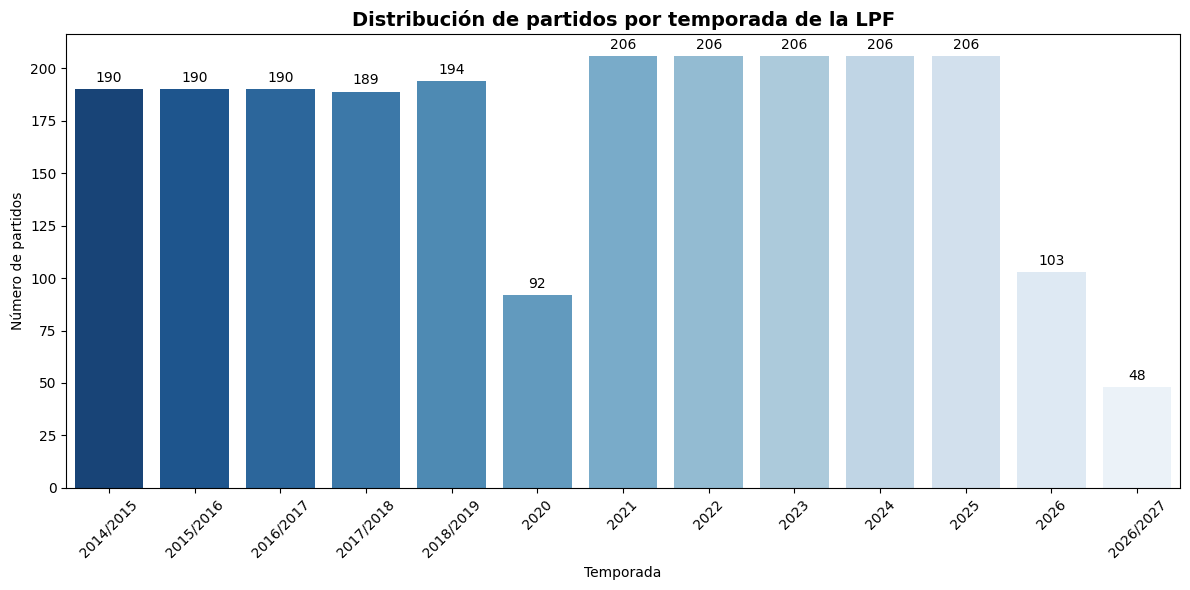

Figura guardada en: C:\Users\ADMIN003\OneDrive - Universidad Tecnológica de Panamá\Escritorio\II SEMESTRE 2026\TESIS\Sistema_Predictivo_LPF\figures\partidos_por_temporada_monocromatico.png


In [11]:
# crear la figura y los ejes para la grafica
fig, ax = plt.subplots(
    figsize=(12, 6)
)

# dibujar el grafico de barras usando una paleta monocromatica de azules
sns.barplot(
    data=partidos_temporada,
    x="temporada",
    y="partidos",
    palette="Blues_r",
    ax=ax
)

# agregar el titulo y las etiquetas de los ejes
ax.set_title(
    "Distribución de partidos por temporada de la LPF",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Temporada")
ax.set_ylabel("Número de partidos")

# rotar las etiquetas del eje x para leerlas mejor
ax.tick_params(
    axis="x",
    rotation=45
)

# mostrar la cantidad exacta sobre cada barra
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%d",
        padding=3
    )

plt.tight_layout()

# definir la ruta donde se guardara la imagen
RUTA_FIGURA = (
    FIGURES_DIR
    / "partidos_por_temporada_monocromatico.png"
)

# guardar la figura en alta resolucion
plt.savefig(
    RUTA_FIGURA,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# confirmar la ruta de guardado
print(
    "Figura guardada en:",
    RUTA_FIGURA
)

### Celda 12. Estadísticos temporales
En esta celda obtengo algunas medidas básicas sobre la distribución de los partidos a lo largo de las temporadas. Esto me permite conocer mejor la cantidad de encuentros registrados y tener una referencia general antes de continuar con el análisis temporal.

In [12]:
# crear una tabla de resumen con las estadisticas de los partidos por temporada
estadisticas_temporales = pd.DataFrame({
    "Indicador": [
        "Número de temporadas/periodos",
        "Partidos totales",
        "Promedio de partidos por periodo",
        "Mínimo de partidos",
        "Máximo de partidos"
    ],
    "Valor": [
        partidos_temporada["temporada"].nunique(),
        partidos_temporada["partidos"].sum(),
        round(
            partidos_temporada["partidos"].mean(),
            2
        ),
        partidos_temporada["partidos"].min(),
        partidos_temporada["partidos"].max()
    ]
})

# mostrar la tabla de estadisticas temporales
display(estadisticas_temporales)

,Indicador,Valor
0,Número de temporadas/periodos,13.00
1,Partidos totales,2226.00
2,Promedio de partidos por periodo,171.23
3,Mínimo de partidos,48.00
4,Máximo de partidos,206.00


### Celda 13. Identificación de los períodos extremos
En esta celda identifico las temporadas que tienen la mayor y la menor cantidad de partidos registrados. Esto me permite reconocer los períodos con una cantidad de encuentros más alta o más baja y revisar si existe alguna diferencia importante entre las temporadas analizadas.

In [13]:
# encontrar la temporada con el minimo de partidos
temporada_min = partidos_temporada.loc[
    partidos_temporada["partidos"].idxmin()
]

# encontrar la temporada con el maximo de partidos
temporada_max = partidos_temporada.loc[
    partidos_temporada["partidos"].idxmax()
]

# mostrar el periodo con menos partidos
print("Periodo con menor cantidad de partidos:")
print(
    temporada_min["temporada"],
    "-",
    temporada_min["partidos"]
)

# mostrar el periodo con mas partidos
print("\nPeriodo con mayor cantidad de partidos:")
print(
    temporada_max["temporada"],
    "-",
    temporada_max["partidos"]
)

Periodo con menor cantidad de partidos:
2026/2027 - 48

Periodo con mayor cantidad de partidos:
2021 - 206


### Celda 14. Evolución anual de los partidos
En esta celda creo una variable temporal a partir del año calendario de cada partido. Esto me permite analizar cómo ha cambiado la cantidad de encuentros a través de los años y utilizar esta información en análisis posteriores sobre goles y resultados. También genero una gráfica para visualizar de forma clara la evolución de los partidos a lo largo del tiempo.

In [14]:
df_eda["anio"] = (
    df_eda["fecha_partido"].dt.year
)

partidos_anio = (
    df_eda
    .groupby("anio")
    .size()
    .rename("partidos")
    .reset_index()
)

display(partidos_anio)

,anio,partidos
0,2014,95
1,2015,190
2,2016,190
3,2017,190
4,2018,191
5,2019,97
6,2020,92
7,2021,206
8,2022,206
9,2023,206


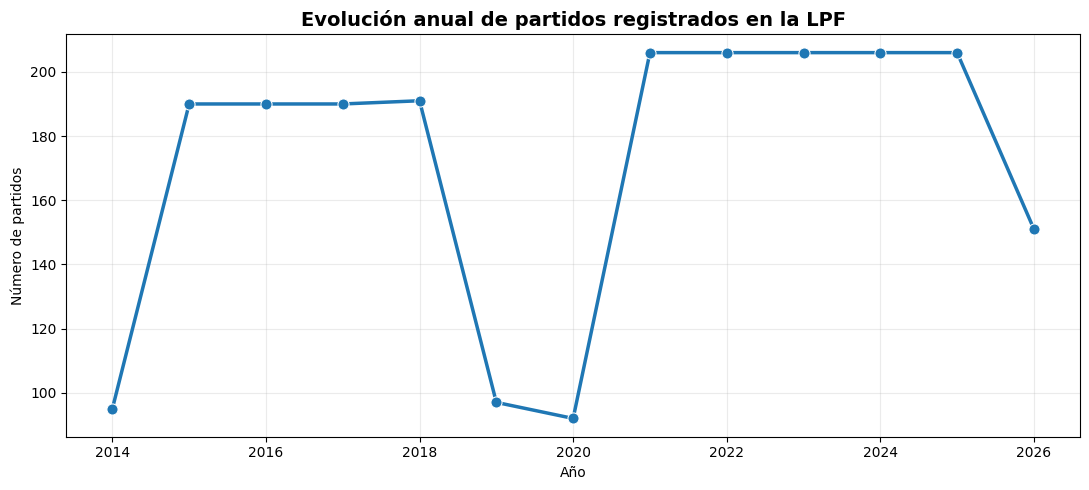

Figura guardada en: C:\Users\ADMIN003\OneDrive - Universidad Tecnológica de Panamá\Escritorio\II SEMESTRE 2026\TESIS\Sistema_Predictivo_LPF\figures\partidos_por_anio.png


In [15]:
# crear la figura y los ejes para la grafica de linea
fig, ax = plt.subplots(
    figsize=(11, 5)
)

# dibujar la linea de evolucion anual con un color azul uniforme
sns.lineplot(
    data=partidos_anio,
    x="anio",
    y="partidos",
    marker="o",
    markersize=8,
    color="#1f77b4",
    linewidth=2.5,
    ax=ax
)

# agregar el titulo y las etiquetas de los ejes
ax.set_title(
    "Evolución anual de partidos registrados en la LPF",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Año")
ax.set_ylabel("Número de partidos")

# configurar la cuadricula suave de fondo
ax.grid(
    alpha=0.25
)

plt.tight_layout()

# definir la ruta para guardar la imagen
RUTA_FIGURA = (
    FIGURES_DIR
    / "partidos_por_anio.png"
)

# guardar la figura en alta resolucion
plt.savefig(
    RUTA_FIGURA,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# confirmar la ruta donde se guardo la imagen
print(
    "Figura guardada en:",
    RUTA_FIGURA
)

## 3. Distribución de la variable objetivo

### Celda 15. Distribución general L/E/V
En esta celda analizo cómo se distribuyen los resultados de los partidos entre las tres categorías: victoria del equipo local (`L`), empate (`E`) y victoria del equipo visitante (`V`). Esto me permite conocer cuál es el resultado más frecuente y comprobar si existe alguna diferencia importante en la cantidad de registros entre las categorías.

In [16]:
# calcular el conteo de cada resultado en orden l, e, v
distribucion_resultados = (
    df_eda["resultado"]
    .value_counts()
    .reindex(["L", "E", "V"])
)

# calcular el porcentaje de cada resultado en orden l, e, v
porcentaje_resultados = (
    df_eda["resultado"]
    .value_counts(normalize=True)
    .reindex(["L", "E", "V"])
    * 100
)

# crear la tabla combinada con conteo y porcentaje
tabla_resultados = pd.DataFrame({
    "partidos": distribucion_resultados,
    "porcentaje": porcentaje_resultados.round(2)
})

# mostrar la tabla con la distribucion de resultados
display(tabla_resultados)

# mostrar la suma total de partidos
print(
    "Total:",
    tabla_resultados["partidos"].sum()
)

,partidos,porcentaje
resultado,,
L,861,38.68
E,699,31.40
V,666,29.92


Total: 2226


### Celda 16. Gráfica de la variable objetivo
En esta celda genero una gráfica que muestra la cantidad de partidos correspondiente a cada resultado: victoria local (`L`), empate (`E`) y victoria visitante (`V`). Esta representación me permite comparar visualmente la frecuencia de cada categoría y observar si existe alguna diferencia importante entre los resultados.

C:\Users\ADMIN003\AppData\Local\Temp\ipykernel_24688\1699534761.py:38: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(


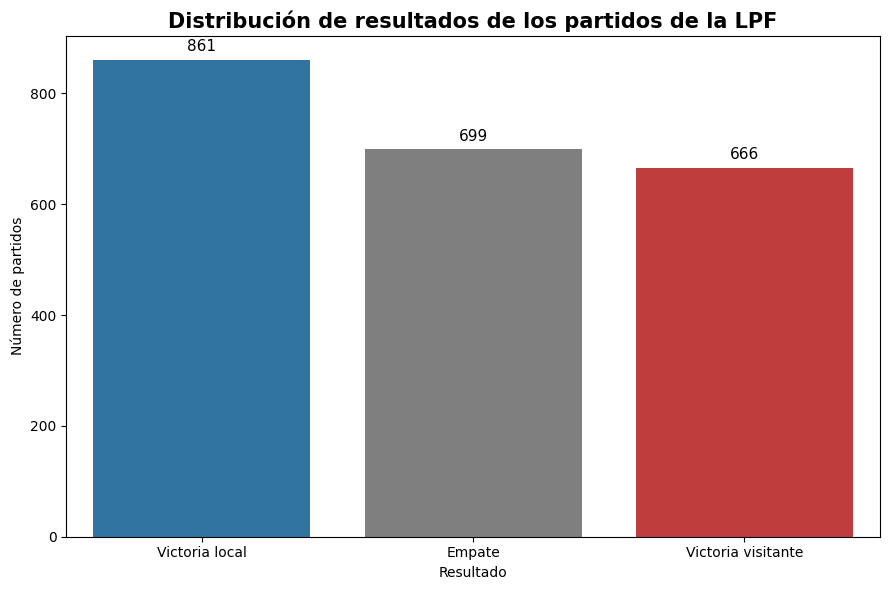

Figura guardada en: C:\Users\ADMIN003\OneDrive - Universidad Tecnológica de Panamá\Escritorio\II SEMESTRE 2026\TESIS\Sistema_Predictivo_LPF\figures\distribucion_resultados.png


In [17]:
# crear la figura y los ejes para la grafica
fig, ax = plt.subplots(
    figsize=(9, 6)
)

orden = ["L", "E", "V"]

# definir la paleta de colores directamente para evitar errores de variable
paleta_colores = {
    "L": "#1f77b4",
    "E": "#7f7f7f",
    "V": "#d62728"
}

# dibujar el grafico de barras asignando el color correspondiente a cada resultado
sns.barplot(
    data=tabla_resultados.reset_index(),
    x="resultado",
    y="partidos",
    order=orden,
    palette=paleta_colores,
    hue="resultado",
    legend=False,
    ax=ax
)

# agregar el titulo y las etiquetas de los ejes
ax.set_title(
    "Distribución de resultados de los partidos de la LPF",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Resultado")
ax.set_ylabel("Número de partidos")

# cambiar los nombres del eje x para facilitar la lectura
ax.set_xticklabels(
    [
        "Victoria local",
        "Empate",
        "Victoria visitante"
    ]
)

# mostrar la cantidad exacta sobre cada barra
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%d",
        padding=4,
        fontsize=11
    )

plt.tight_layout()

# definir la ruta para guardar la figura
RUTA_FIGURA = (
    FIGURES_DIR
    / "distribucion_resultados.png"
)

# guardar la figura en alta resolucion
plt.savefig(
    RUTA_FIGURA,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# confirmar la ruta de guardado
print(
    "Figura guardada en:",
    RUTA_FIGURA
)

### Celda 17. Diferencias entre clases
En esta celda cuantifico las diferencias en la cantidad de partidos entre las tres categorías de resultado. Esto me permite conocer qué tan equilibrada está la variable objetivo y comprobar si alguna clase tiene una representación mucho mayor o menor que las demás.

In [18]:
clase_mayoritaria = (
    distribucion_resultados.idxmax()
)

clase_minoritaria = (
    distribucion_resultados.idxmin()
)

cantidad_mayoritaria = (
    distribucion_resultados.max()
)

cantidad_minoritaria = (
    distribucion_resultados.min()
)

diferencia_absoluta = (
    cantidad_mayoritaria
    - cantidad_minoritaria
)

razon_desbalance = (
    cantidad_mayoritaria
    / cantidad_minoritaria
)

print(
    "Clase mayoritaria:",
    clase_mayoritaria,
    "-",
    cantidad_mayoritaria
)

print(
    "Clase minoritaria:",
    clase_minoritaria,
    "-",
    cantidad_minoritaria
)

print(
    "Diferencia absoluta:",
    diferencia_absoluta
)

print(
    "Razón mayoritaria/minoritaria:",
    round(razon_desbalance, 3)
)

Clase mayoritaria: L - 861
Clase minoritaria: V - 666
Diferencia absoluta: 195
Razón mayoritaria/minoritaria: 1.293


### Celda 18. Distribución de resultados por temporada
En esta celda calculo el conteo y el porcentaje de victorias locales, empates y victorias visitantes para cada una de las temporadas registradas. Esto me permite analizar cómo ha cambiado el comportamiento de los resultados a lo largo del tiempo y evaluar si la ventaja de jugar en casa se mantiene constante en los distintos torneos.

In [19]:
# agrupar los datos por temporada y calcular la cantidad de partidos por cada resultado
resultados_temporada = (
    df_eda
    .groupby(["temporada", "resultado"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=["L", "E", "V"])
)

# calcular el porcentaje de cada resultado por temporada
porcentaje_resultados_temporada = (
    resultados_temporada
    .div(resultados_temporada.sum(axis=1), axis=0)
    * 100
).round(2)

# combinar conteo y porcentaje en un solo dataframe para facilitar la lectura
tabla_resultados_temporada = resultados_temporada.copy()
for col in ["L", "E", "V"]:
    tabla_resultados_temporada[f"%_{col}"] = porcentaje_resultados_temporada[col]

# ordenar las columnas para mostrar primero el conteo y luego el porcentaje de cada resultado
columnas_ordenadas = ["L", "%_L", "E", "%_E", "V", "%_V"]
tabla_resultados_temporada = tabla_resultados_temporada[columnas_ordenadas]

# mostrar la tabla completa de resultados por temporada
display(tabla_resultados_temporada)

resultado,L,%_L,E,%_E,V,%_V
temporada,,,,,,
2014/2015,68,35.79,59,31.05,63,33.16
2015/2016,86,45.26,51,26.84,53,27.89
2016/2017,72,37.89,54,28.42,64,33.68
2017/2018,81,42.86,65,34.39,43,22.75
2018/2019,69,35.57,56,28.87,69,35.57
2020,34,36.96,32,34.78,26,28.26
2021,73,35.44,75,36.41,58,28.16
2022,75,36.41,65,31.55,66,32.04
2023,87,42.23,58,28.16,61,29.61


In [20]:
resultados_temporada_pct = (
    resultados_temporada
    .div(
        resultados_temporada.sum(axis=1),
        axis=0
    )
    * 100
)

display(
    resultados_temporada_pct.round(2)
)

resultado,L,E,V
temporada,,,
2014/2015,35.79,31.05,33.16
2015/2016,45.26,26.84,27.89
2016/2017,37.89,28.42,33.68
2017/2018,42.86,34.39,22.75
2018/2019,35.57,28.87,35.57
2020,36.96,34.78,28.26
2021,35.44,36.41,28.16
2022,36.41,31.55,32.04
2023,42.23,28.16,29.61


## Celda 19. Evolución porcentual de resultados por temporada
En esta celda calculo la proporción porcentual de victorias locales, empates y victorias visitantes para cada temporada y genero un gráfico de líneas para visualizar su evolución temporal. Esto me permite identificar tendencias en el rendimiento de los equipos en casa y analizar cómo ha variado la ventaja de localía a lo largo de los torneos de la LPF.

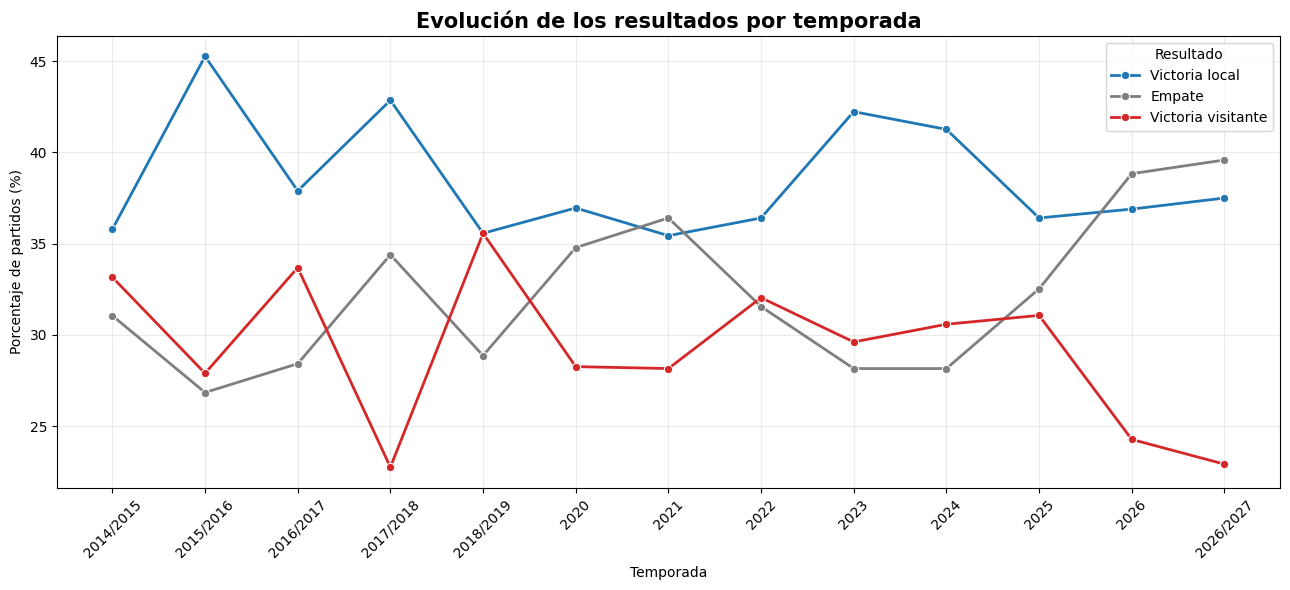

Figura guardada en: C:\Users\ADMIN003\OneDrive - Universidad Tecnológica de Panamá\Escritorio\II SEMESTRE 2026\TESIS\Sistema_Predictivo_LPF\figures\resultados_por_temporada.png


In [21]:
# transformar la tabla de porcentajes a formato largo para graficar
resultados_pct_plot = (
    resultados_temporada_pct
    .reset_index()
    .melt(
        id_vars="temporada",
        var_name="resultado",
        value_name="porcentaje"
    )
)

# mapear los codigos a nombres mas descriptivos
etiquetas_resultado = {
    "L": "Victoria local",
    "E": "Empate",
    "V": "Victoria visitante"
}

resultados_pct_plot[
    "resultado_nombre"
] = resultados_pct_plot[
    "resultado"
].map(etiquetas_resultado)

# definir la paleta de colores personalizada para los resultados
paleta_resultados = {
    "Victoria local": "#1f77b4",
    "Empate": "#7f7f7f",
    "Victoria visitante": "#d62728"
}

# crear la figura y los ejes para la grafica
fig, ax = plt.subplots(
    figsize=(13, 6)
)

# dibujar las lineas de tendencia aplicando la paleta de colores
sns.lineplot(
    data=resultados_pct_plot,
    x="temporada",
    y="porcentaje",
    hue="resultado_nombre",
    palette=paleta_resultados,
    marker="o",
    linewidth=2,
    ax=ax
)

# agregar el titulo y las etiquetas de los ejes
ax.set_title(
    "Evolución de los resultados por temporada",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Temporada")
ax.set_ylabel("Porcentaje de partidos (%)")

# rotar las etiquetas del eje x para facilitar la lectura
ax.tick_params(
    axis="x",
    rotation=45
)

# configurar la leyenda y la cuadricula suave
ax.legend(
    title="Resultado"
)

ax.grid(
    alpha=0.25
)

plt.tight_layout()

# definir la ruta para guardar la figura
RUTA_FIGURA = (
    FIGURES_DIR
    / "resultados_por_temporada.png"
)

# guardar la figura en alta resolucion
plt.savefig(
    RUTA_FIGURA,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# confirmar la ruta donde se guardo la imagen
print(
    "Figura guardada en:",
    RUTA_FIGURA
)

## Celda 20. Cuantificación directa de la ventaja de localía
En esta celda cuantifico directamente la ventaja de jugar en casa calculando la proporción de puntos obtenidos por los equipos locales frente a los visitantes, así como el porcentaje de victorias en casa sobre el total de partidos decididos. Esta métrica me permite medir de forma precisa el impacto del factor cancha en la LPF a lo largo del tiempo.

In [22]:
# calcular la cantidad y porcentaje de cada resultado en la tabla de resumen
resumen_localia = pd.DataFrame({
    "resultado": [
        "Victoria local",
        "Empate",
        "Victoria visitante"
    ],
    "partidos": [
        (df_eda["resultado"] == "L").sum(),
        (df_eda["resultado"] == "E").sum(),
        (df_eda["resultado"] == "V").sum()
    ]
})

resumen_localia["porcentaje"] = (
    resumen_localia["partidos"]
    / len(df_eda)
    * 100
).round(2)

# mostrar el resumen general de localia
display(resumen_localia)

,resultado,partidos,porcentaje
0,Victoria local,861,38.68
1,Empate,699,31.40
2,Victoria visitante,666,29.92


In [23]:
porcentaje_local = (
    (df_eda["resultado"] == "L").mean()
    * 100
)

porcentaje_visitante = (
    (df_eda["resultado"] == "V").mean()
    * 100
)

diferencia_localia = (
    porcentaje_local
    - porcentaje_visitante
)

print(
    "Victorias locales:",
    round(porcentaje_local, 2),
    "%"
)

print(
    "Victorias visitantes:",
    round(porcentaje_visitante, 2),
    "%"
)

print(
    "Diferencia a favor del local:",
    round(diferencia_localia, 2),
    "puntos porcentuales"
)

Victorias locales: 38.68 %
Victorias visitantes: 29.92 %
Diferencia a favor del local: 8.76 puntos porcentuales


## Celda 20.1 Baseline de clase mayoritaria
### 3.1. Línea base de clasificación
Como referencia mínima de desempeño, calculo la exactitud que obtendría un clasificador elemental que asignara a todos los partidos la categoría más frecuente del conjunto histórico. Esta línea base será utilizada posteriormente para determinar si los modelos predictivos aportan una mejora real sobre una estrategia trivial.

In [24]:
# identificar la clase mayoritaria dentro de los resultados
clase_mayoritaria = (
    df_eda["resultado"]
    .value_counts()
    .idxmax()
)

# calcular la proporcion de la clase mayoritaria como baseline
baseline_accuracy = (
    df_eda["resultado"]
    .value_counts(normalize=True)
    .max()
)

# mostrar la clase mas frecuente
print(
    "Clase mayoritaria:",
    clase_mayoritaria
)

# mostrar el porcentaje de exactitud base
print(
    "Accuracy baseline:",
    round(
        baseline_accuracy * 100,
        2
    ),
    "%"
)

Clase mayoritaria: L
Accuracy baseline: 38.68 %


# 4. Análisis de goles
# Celda 21 Estadísticas descriptivas de goles
## 4. Análisis de la distribución de goles
El número de goles constituye una de las variables fundamentales del sistema predictivo, particularmente para el modelo basado en la Distribución de Poisson. En esta sección se analiza la frecuencia de anotación de los equipos locales y visitantes, la cantidad total de goles por encuentro, los marcadores más frecuentes y su comportamiento a través de las temporadas.

In [25]:
# calcular las estadisticas descriptivas de los goles locales, visitantes y totales
estadisticas_goles = (
    df_eda[
        [
            "home_team_goal_count",
            "away_team_goal_count",
            "total_goal_count"
        ]
    ]
    .describe()
    .round(3)
)

# mostrar la tabla descriptiva de goles
display(estadisticas_goles)

,home_team_goal_count,away_team_goal_count,total_goal_count
count,2226.000,2226.000,2226.000
mean,1.214,1.044,2.258
std,1.124,1.037,1.564
min,0.000,0.000,0.000
25%,0.000,0.000,1.000
50%,1.000,1.000,2.000
75%,2.000,2.000,3.000
max,9.000,6.000,9.000


In [26]:
print(
    "Promedio de goles locales:",
    round(
        df_eda[
            "home_team_goal_count"
        ].mean(),
        3
    )
)

print(
    "Promedio de goles visitantes:",
    round(
        df_eda[
            "away_team_goal_count"
        ].mean(),
        3
    )
)

print(
    "Promedio total de goles:",
    round(
        df_eda[
            "total_goal_count"
        ].mean(),
        3
    )
)

print(
    "Mediana total de goles:",
    df_eda[
        "total_goal_count"
    ].median()
)

Promedio de goles locales: 1.214
Promedio de goles visitantes: 1.044
Promedio total de goles: 2.258
Mediana total de goles: 2.0


# Celda 22. Distribución del total de goles por partido
En esta celda analizo la frecuencia y distribución de los goles totales anotados por partido en la LPF. Genero un gráfico de barras para visualizar qué tan comunes son los marcadores según la cantidad total de goles y calculo las métricas de tendencia central para caracterizar la efectividad goleadora de la liga.

In [27]:
distribucion_goles = (
    df_eda["total_goal_count"]
    .value_counts()
    .sort_index()
    .rename("partidos")
    .reset_index()
)

distribucion_goles.columns = [
    "total_goles",
    "partidos"
]

distribucion_goles[
    "porcentaje"
] = (
    distribucion_goles[
        "partidos"
    ]
    / len(df_eda)
    * 100
).round(2)

display(distribucion_goles)

,total_goles,partidos,porcentaje
0,0,275,12.35
1,1,501,22.51
2,2,555,24.93
3,3,457,20.53
4,4,255,11.46
5,5,111,4.99
6,6,47,2.11
7,7,17,0.76
8,8,4,0.18
9,9,4,0.18


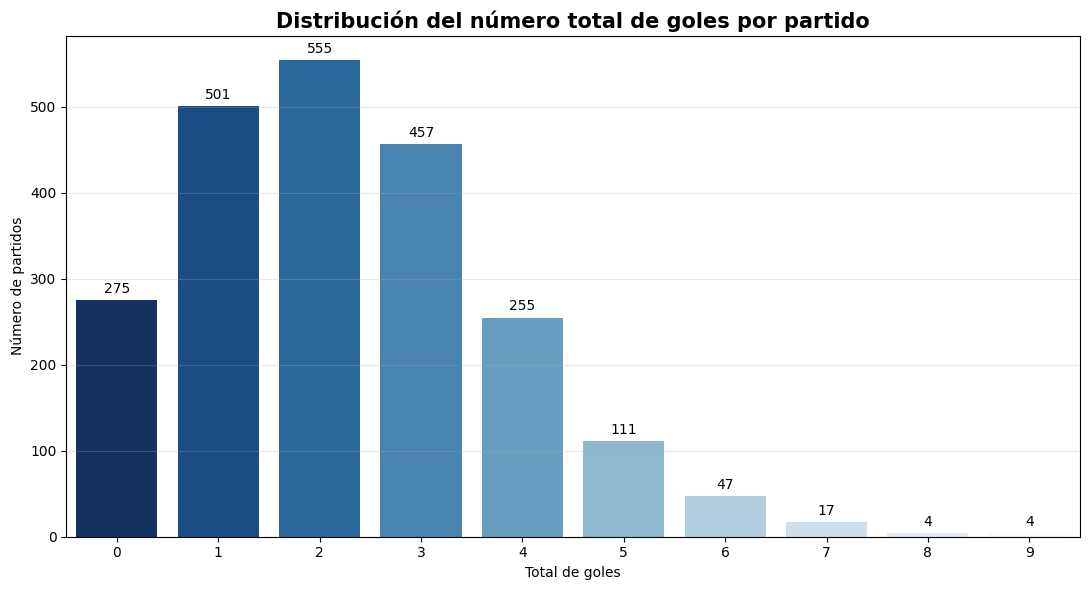

Figura guardada en: C:\Users\ADMIN003\OneDrive - Universidad Tecnológica de Panamá\Escritorio\II SEMESTRE 2026\TESIS\Sistema_Predictivo_LPF\figures\distribucion_total_goles.png


In [29]:
# crear la figura y los ejes para la grafica
fig, ax = plt.subplots(
    figsize=(11, 6)
)

# dibujar el grafico de barras aplicando una paleta monocromatica de azules
sns.barplot(
    data=distribucion_goles,
    x="total_goles",
    y="partidos",
    palette="Blues_r",
    hue="total_goles",
    legend=False,
    ax=ax
)

# agregar el titulo y las etiquetas de los ejes
ax.set_title(
    "Distribución del número total de goles por partido",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Total de goles")
ax.set_ylabel("Número de partidos")

# colocar el conteo exacto sobre cada barra
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%d",
        padding=3
    )

# configurar la cuadricula suave de fondo
ax.grid(
    axis="y",
    alpha=0.25
)

plt.tight_layout()

# definir la ruta para guardar la figura
RUTA_FIGURA = (
    FIGURES_DIR
    / "distribucion_total_goles.png"
)

# guardar la figura en alta resolucion
plt.savefig(
    RUTA_FIGURA,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# confirmar la ruta de guardado
print(
    "Figura guardada en:",
    RUTA_FIGURA
)

 # Celda 23. Comparación del promedio de goles entre locales y visitantes
En esta celda calculo y comparo el promedio de goles anotados por los equipos locales frente a los visitantes. Esta métrica me permite verificar la efectividad ofensiva según la condición del equipo y determinar de forma cuantitativa la ventaja que otorga jugar en casa en términos de goles marcados.

In [30]:
# calcular el promedio de goles para equipos locales y visitantes
promedios_goles = pd.DataFrame({
    "condicion": [
        "Equipo local",
        "Equipo visitante"
    ],
    "promedio_goles": [
        df_eda[
            "home_team_goal_count"
        ].mean(),

        df_eda[
            "away_team_goal_count"
        ].mean()
    ]
})

# redondear los valores a tres decimales para facilitar la lectura
promedios_goles[
    "promedio_goles"
] = promedios_goles[
    "promedio_goles"
].round(3)

# mostrar la tabla comparativa de promedios de goles
display(promedios_goles)

,condicion,promedio_goles
0,Equipo local,1.214
1,Equipo visitante,1.044


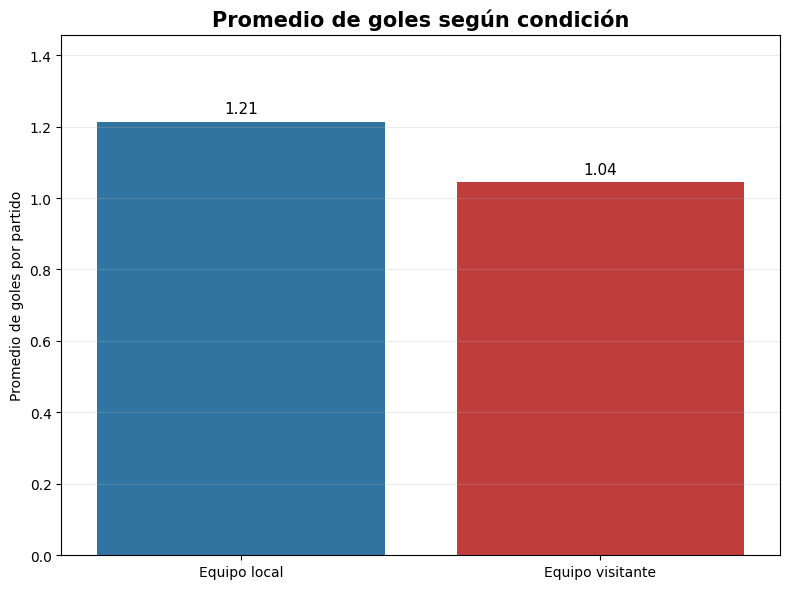

Figura guardada en: C:\Users\ADMIN003\OneDrive - Universidad Tecnológica de Panamá\Escritorio\II SEMESTRE 2026\TESIS\Sistema_Predictivo_LPF\figures\promedio_goles_local_visitante.png


In [32]:
# crear la figura y los ejes para la grafica
fig, ax = plt.subplots(
    figsize=(8, 6)
)

# definir la paleta de colores para diferenciar local y visitante
paleta_condicion = {
    "Equipo local": "#1f77b4",
    "Equipo visitante": "#d62728"
}

# dibujar el grafico de barras con la paleta personalizada
sns.barplot(
    data=promedios_goles,
    x="condicion",
    y="promedio_goles",
    palette=paleta_condicion,
    hue="condicion",
    legend=False,
    ax=ax
)

# agregar el titulo y las etiquetas de los ejes
ax.set_title(
    "Promedio de goles según condición",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("")
ax.set_ylabel("Promedio de goles por partido")

# ajustar el limite superior para dar espacio a las etiquetas
max_val = promedios_goles["promedio_goles"].max()
ax.set_ylim(0, max_val * 1.2)

# mostrar el valor exacto sobre cada barra
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.2f",
        padding=4,
        fontsize=11
    )

# agregar cuadricula suave en el eje y
ax.grid(
    axis="y",
    alpha=0.25
)

plt.tight_layout()

# definir la ruta para guardar la figura
RUTA_FIGURA = (
    FIGURES_DIR
    / "promedio_goles_local_visitante.png"
)

# guardar la figura en alta resolucion
plt.savefig(
    RUTA_FIGURA,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# confirmar la ruta de guardado
print(
    "Figura guardada en:",
    RUTA_FIGURA
)

# Celda 24. Marcadores exactos más frecuentes
En esta celda agrupo los datos según la cantidad de goles del equipo local y visitante para identificar los marcadores exactos más recurrentes en la LPF. Muestro una tabla con los quince resultados más comunes junto con su conteo de partidos y el porcentaje que representan sobre el total de encuentros.

In [33]:
# agrupar los datos por goles locales y visitantes para contar marcadores exactos
marcadores_frecuentes = (
    df_eda
    .groupby(
        [
            "home_team_goal_count",
            "away_team_goal_count"
        ]
    )
    .size()
    .rename("partidos")
    .reset_index()
)

# crear el string representativo del marcador exacto
marcadores_frecuentes[
    "marcador"
] = (
    marcadores_frecuentes[
        "home_team_goal_count"
    ].astype(str)
    + "-"
    + marcadores_frecuentes[
        "away_team_goal_count"
    ].astype(str)
)

# calcular el porcentaje que representa cada marcador exacto
marcadores_frecuentes[
    "porcentaje"
] = (
    marcadores_frecuentes[
        "partidos"
    ]
    / len(df_eda)
    * 100
).round(2)

# obtener los 15 marcadores exactos mas frecuentes
top_marcadores = (
    marcadores_frecuentes
    .sort_values(
        "partidos",
        ascending=False
    )
    .head(15)
    .reset_index(drop=True)
)

# mostrar la tabla con los marcadores mas frecuentes
display(
    top_marcadores[
        [
            "marcador",
            "partidos",
            "porcentaje"
        ]
    ]
)

,marcador,partidos,porcentaje
0,1-1,295,13.25
1,1-0,276,12.40
2,0-0,275,12.35
3,0-1,225,10.11
4,2-1,199,8.94
5,1-2,165,7.41
6,2-0,146,6.56
7,0-2,114,5.12
8,2-2,109,4.90
9,3-0,61,2.74


# Celda 25. Gráfica de marcadores exactos más frecuentes
En esta celda creo un gráfico de barras para visualizar los quince marcadores exactos más comunes en la LPF. Aplico una paleta de colores degradada basada en la frecuencia de cada resultado para resaltar los marcadores más habituales y guardo la figura final en la carpeta correspondiente.

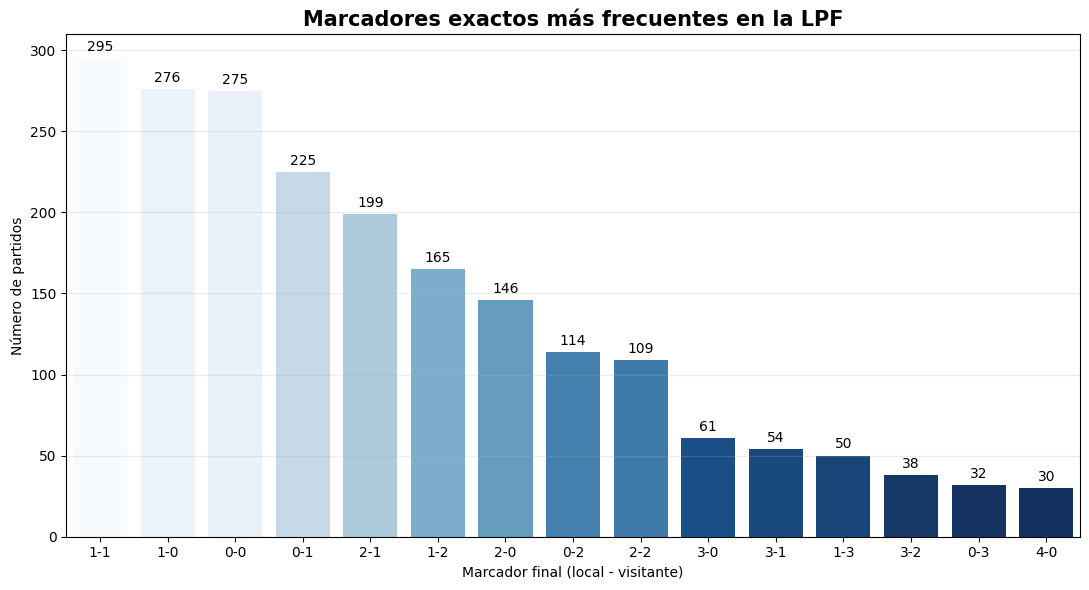

Figura guardada en: C:\Users\ADMIN003\OneDrive - Universidad Tecnológica de Panamá\Escritorio\II SEMESTRE 2026\TESIS\Sistema_Predictivo_LPF\figures\marcadores_frecuentes.png


In [34]:
# crear la figura y los ejes para la grafica
fig, ax = plt.subplots(
    figsize=(11, 6)
)

# dibujar el grafico de barras aplicando una paleta degradada por frecuencia
sns.barplot(
    data=top_marcadores,
    x="marcador",
    y="partidos",
    palette="Blues_r",
    hue="partidos",
    legend=False,
    ax=ax
)

# agregar el titulo y las etiquetas de los ejes
ax.set_title(
    "Marcadores exactos más frecuentes en la LPF",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Marcador final (local - visitante)")
ax.set_ylabel("Número de partidos")

# colocar el conteo exacto sobre cada barra
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%d",
        padding=3,
        fontsize=10
    )

# agregar cuadricula suave en el eje y
ax.grid(
    axis="y",
    alpha=0.25
)

plt.tight_layout()

# definir la ruta para guardar la figura
RUTA_FIGURA = (
    FIGURES_DIR
    / "marcadores_frecuentes.png"
)

# guardar la figura en alta resolucion
plt.savefig(
    RUTA_FIGURA,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# confirmar la ruta donde se guardo la imagen
print(
    "Figura guardada en:",
    RUTA_FIGURA
)

# Celda 26. Evolución del promedio de goles por temporada
En esta celda agrupo los datos por temporada para calcular el promedio de goles anotados por el equipo local, el equipo visitante y el total por encuentro. Esta agregación me permite analizar la evolución de la efectividad goleadora de la LPF a lo largo del tiempo e identificar temporadas con mayor o menor cuota goleadora.

In [35]:
# agrupar por temporada y calcular los promedios de goles locales, visitantes y totales
goles_temporada = (
    df_eda
    .groupby("temporada")
    .agg(
        promedio_local=(
            "home_team_goal_count",
            "mean"
        ),
        promedio_visitante=(
            "away_team_goal_count",
            "mean"
        ),
        promedio_total=(
            "total_goal_count",
            "mean"
        )
    )
    .round(3)
    .reset_index()
)

# mostrar la tabla con la evolucion de promedios de goles
display(goles_temporada)

,temporada,promedio_local,promedio_visitante,promedio_total
0,2014/2015,1.168,1.121,2.289
1,2015/2016,1.179,1.005,2.184
2,2016/2017,1.053,1.026,2.079
3,2017/2018,1.238,0.889,2.127
4,2018/2019,1.155,1.124,2.278
5,2020,1.098,0.957,2.054
6,2021,1.078,0.913,1.990
7,2022,1.141,1.049,2.189
8,2023,1.417,1.053,2.471
9,2024,1.209,1.053,2.262


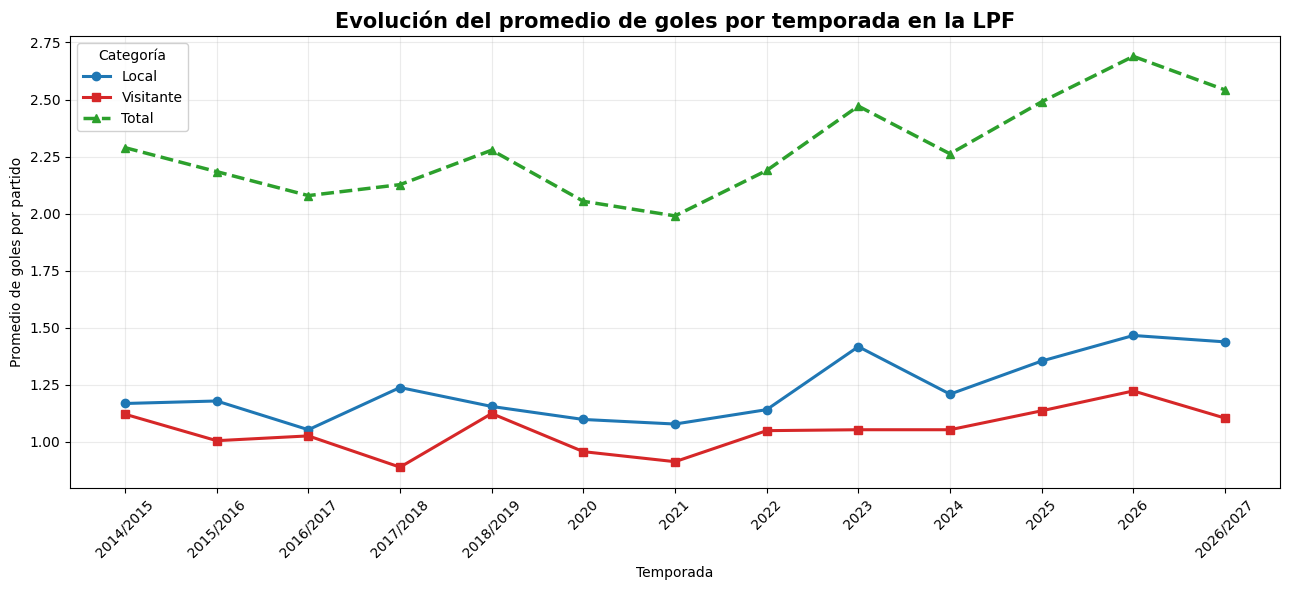

Figura guardada en: C:\Users\ADMIN003\OneDrive - Universidad Tecnológica de Panamá\Escritorio\II SEMESTRE 2026\TESIS\Sistema_Predictivo_LPF\figures\goles_promedio_por_temporada.png


In [36]:
# crear la figura y los ejes para la grafica
fig, ax = plt.subplots(
    figsize=(13, 6)
)

# graficar la evolucion del promedio de goles locales
ax.plot(
    goles_temporada["temporada"],
    goles_temporada["promedio_local"],
    marker="o",
    linewidth=2.2,
    color="#1f77b4",
    label="Local"
)

# graficar la evolucion del promedio de goles visitantes
ax.plot(
    goles_temporada["temporada"],
    goles_temporada["promedio_visitante"],
    marker="s",
    linewidth=2.2,
    color="#d62728",
    label="Visitante"
)

# graficar la evolucion del promedio de goles totales
ax.plot(
    goles_temporada["temporada"],
    goles_temporada["promedio_total"],
    marker="^",
    linewidth=2.5,
    linestyle="--",
    color="#2ca02c",
    label="Total"
)

# agregar el titulo y las etiquetas de los ejes
ax.set_title(
    "Evolución del promedio de goles por temporada en la LPF",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Temporada")
ax.set_ylabel("Promedio de goles por partido")

# rotar las etiquetas del eje x para facilitar la lectura
ax.tick_params(
    axis="x",
    rotation=45
)

# configurar la leyenda y la cuadricula suave
ax.legend(
    title="Categoría",
    frameon=True,
    facecolor="white",
    framealpha=0.9
)

ax.grid(
    alpha=0.25
)

plt.tight_layout()

# definir la ruta para guardar la figura
RUTA_FIGURA = (
    FIGURES_DIR
    / "goles_promedio_por_temporada.png"
)

# guardar la figura en alta resolucion
plt.savefig(
    RUTA_FIGURA,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# confirmar la ruta de guardado
print(
    "Figura guardada en:",
    RUTA_FIGURA
)

## Celda 28. Diagnóstico preliminar para el supuesto de distribución de Poisson 
En esta celda evalúo la propiedad de equidispensión  las variables de goles locales, visitantes y totales mediante el cálculo del índice de dispersión. Este diagnóstico me permite verificar si la distribución de Poisson es adecuada para modelar el número de goles en la LPF o si existe presencia de sobredispersión o subdispersión en los datos.

In [37]:
# calcular media, varianza e indice de dispersion para evaluar la distribucion de poisson
diagnostico_poisson = pd.DataFrame({
    "variable": [
        "Goles local",
        "Goles visitante",
        "Goles totales"
    ],

    "media": [
        df_eda[
            "home_team_goal_count"
        ].mean(),

        df_eda[
            "away_team_goal_count"
        ].mean(),

        df_eda[
            "total_goal_count"
        ].mean()
    ],

    "varianza": [
        df_eda[
            "home_team_goal_count"
        ].var(),

        df_eda[
            "away_team_goal_count"
        ].var(),

        df_eda[
            "total_goal_count"
        ].var()
    ]
})

# calcular el indice de dispersion (varianza / media)
diagnostico_poisson[
    "indice_dispersion"
] = (
    diagnostico_poisson[
        "varianza"
    ]
    / diagnostico_poisson[
        "media"
    ]
)

# mostrar la tabla con el diagnostico redondeado a tres decimales
display(
    diagnostico_poisson.round(3)
)

,variable,media,varianza,indice_dispersion
0,Goles local,1.214,1.264,1.041
1,Goles visitante,1.044,1.076,1.030
2,Goles totales,2.258,2.448,1.084


# Celda 29
### 4.1. Comparación exploratoria con la distribución de Poisson
Para complementar el análisis del índice de dispersión, comparo las frecuencias observadas de goles con las probabilidades esperadas bajo una distribución de Poisson parametrizada mediante la media histórica. Esta evaluación es de carácter exploratorio y no sustituye la validación predictiva del modelo.

In [38]:
from scipy.stats import poisson

# calcular el parametro lambda y el rango de goles locales
lambda_local = (
    df_eda["home_team_goal_count"].mean()
)

max_goles_local = (
    df_eda["home_team_goal_count"].max()
)

valores_local = np.arange(
    0,
    max_goles_local + 1
)

# frecuencia observada de goles locales
observado_local = (
    df_eda["home_team_goal_count"]
    .value_counts()
    .reindex(
        valores_local,
        fill_value=0
    )
    .sort_index()
)

# frecuencia esperada mediante la funcion de masa de probabilidad de Poisson
esperado_local = (
    poisson.pmf(
        valores_local,
        mu=lambda_local
    )
    * len(df_eda)
)

# construir el dataframe de comparacion
comparacion_local = pd.DataFrame({
    "goles": valores_local,
    "observado": observado_local.values,
    "esperado_poisson": esperado_local
})

# mostrar la tabla comparativa redondeada
display(
    comparacion_local.round(2)
)

,goles,observado,esperado_poisson
0,0,663,661.25
1,1,808,802.64
2,2,490,487.14
3,3,177,197.10
4,4,69,59.81
5,5,13,14.52
6,6,3,2.94
7,7,1,0.51
8,8,1,0.08
9,9,1,0.01


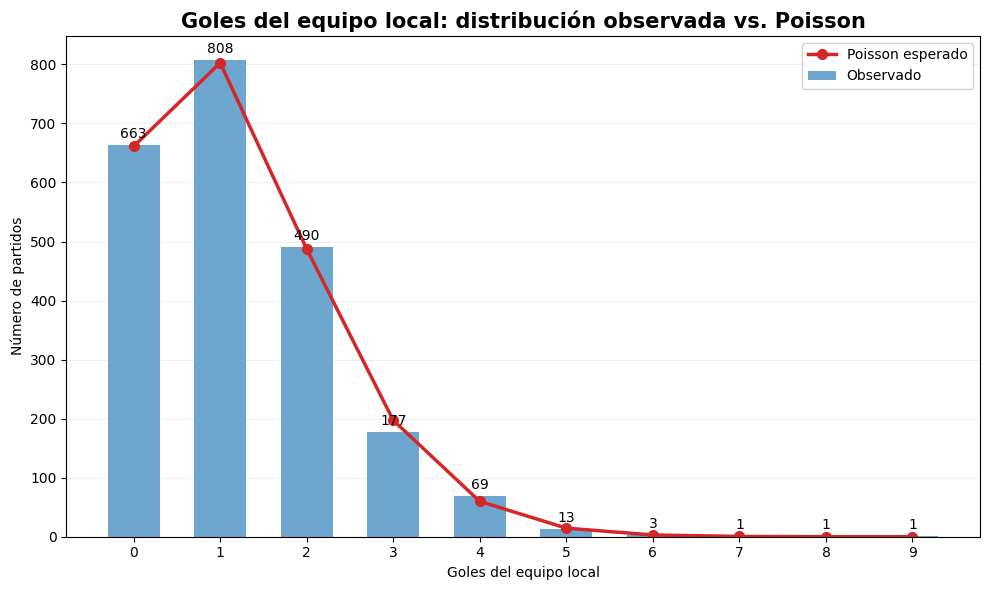

Figura guardada en: C:\Users\ADMIN003\OneDrive - Universidad Tecnológica de Panamá\Escritorio\II SEMESTRE 2026\TESIS\Sistema_Predictivo_LPF\figures\poisson_goles_local.png


In [39]:
# crear la figura y los ejes para la grafica
fig, ax = plt.subplots(
    figsize=(10, 6)
)

# graficar las frecuencias observadas como barras
barras = ax.bar(
    comparacion_local["goles"],
    comparacion_local["observado"],
    color="#1f77b4",
    alpha=0.65,
    width=0.6,
    label="Observado"
)

# graficar las frecuencias esperadas por Poisson como linea con marcadores
linea = ax.plot(
    comparacion_local["goles"],
    comparacion_local["esperado_poisson"],
    color="#d62728",
    marker="o",
    linewidth=2.5,
    markersize=7,
    label="Poisson esperado"
)

# agregar el titulo y las etiquetas de los ejes
ax.set_title(
    "Goles del equipo local: distribución observada vs. Poisson",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Goles del equipo local")
ax.set_ylabel("Número de partidos")

# asegurar que todas las cantidades de goles aparezcan en el eje x
ax.set_xticks(comparacion_local["goles"])

# colocar etiquetas numericas sobre las barras
ax.bar_label(
    barras,
    fmt="%d",
    padding=3,
    fontsize=10
)

# configurar la leyenda y la cuadricula suave
ax.legend(
    frameon=True,
    facecolor="white",
    framealpha=0.9
)

ax.grid(
    axis="y",
    alpha=0.20
)

plt.tight_layout()

# definir la ruta para guardar la figura
RUTA_FIGURA = (
    FIGURES_DIR
    / "poisson_goles_local.png"
)

# guardar la figura en alta resolucion
plt.savefig(
    RUTA_FIGURA,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# confirmar la ruta de guardado
print(
    "Figura guardada en:",
    RUTA_FIGURA
)

# Celda 30. Comparación de la distribución observada vs. teórica de Poisson para goles visitantes
En esta celda calculo la frecuencia esperada de goles de los equipos visitantes bajo el supuesto de una distribución de Poisson utilizando el parámetro obtenido de la media de goles visitantes. Luego construyo una tabla comparativa entre las frecuencias observadas en los partidos de la LPF y las calculadas por el modelo teórico.

In [40]:
# calcular el parametro lambda y el rango de goles visitantes
lambda_visitante = (
    df_eda["away_team_goal_count"].mean()
)

max_goles_visitante = (
    df_eda["away_team_goal_count"].max()
)

valores_visitante = np.arange(
    0,
    max_goles_visitante + 1
)

# frecuencia observada de goles visitantes
observado_visitante = (
    df_eda["away_team_goal_count"]
    .value_counts()
    .reindex(
        valores_visitante,
        fill_value=0
    )
    .sort_index()
)

# frecuencia esperada mediante Poisson
esperado_visitante = (
    poisson.pmf(
        valores_visitante,
        mu=lambda_visitante
    )
    * len(df_eda)
)

# construir el dataframe de comparacion para equipos visitantes
comparacion_visitante = pd.DataFrame({
    "goles": valores_visitante,
    "observado": observado_visitante.values,
    "esperado_poisson": esperado_visitante
})

# mostrar la tabla comparativa redondeada
display(
    comparacion_visitante.round(2)
)

,goles,observado,esperado_poisson
0,0,795,783.63
1,1,798,818.13
2,2,445,427.07
3,3,134,148.63
4,4,41,38.79
5,5,8,8.10
6,6,5,1.41


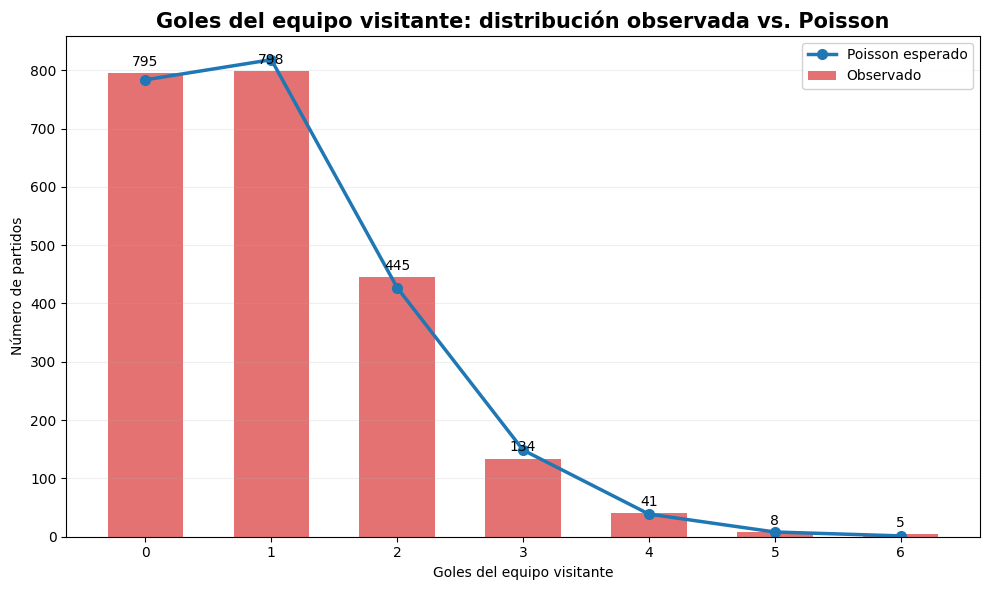

Figura guardada en: C:\Users\ADMIN003\OneDrive - Universidad Tecnológica de Panamá\Escritorio\II SEMESTRE 2026\TESIS\Sistema_Predictivo_LPF\figures\poisson_goles_visitante.png


In [41]:
# crear la figura y los ejes para la grafica
fig, ax = plt.subplots(
    figsize=(10, 6)
)

# graficar las frecuencias observadas como barras para el equipo visitante
barras = ax.bar(
    comparacion_visitante["goles"],
    comparacion_visitante["observado"],
    color="#d62728",
    alpha=0.65,
    width=0.6,
    label="Observado"
)

# graficar las frecuencias esperadas por Poisson como linea con marcadores
linea = ax.plot(
    comparacion_visitante["goles"],
    comparacion_visitante["esperado_poisson"],
    color="#1f77b4",
    marker="o",
    linewidth=2.5,
    markersize=7,
    label="Poisson esperado"
)

# agregar el titulo y las etiquetas de los ejes
ax.set_title(
    "Goles del equipo visitante: distribución observada vs. Poisson",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Goles del equipo visitante")
ax.set_ylabel("Número de partidos")

# asegurar que todas las cantidades de goles aparezcan en el eje x
ax.set_xticks(comparacion_visitante["goles"])

# colocar etiquetas numericas sobre las barras
ax.bar_label(
    barras,
    fmt="%d",
    padding=3,
    fontsize=10
)

# configurar la leyenda y la cuadricula suave
ax.legend(
    frameon=True,
    facecolor="white",
    framealpha=0.9
)

ax.grid(
    axis="y",
    alpha=0.20
)

plt.tight_layout()

# definir la ruta para guardar la figura
RUTA_FIGURA = (
    FIGURES_DIR
    / "poisson_goles_visitante.png"
)

# guardar la figura en alta resolucion
plt.savefig(
    RUTA_FIGURA,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# confirmar la ruta de guardado
print(
    "Figura guardada en:",
    RUTA_FIGURA
)

# Celda 31
### 4.2. Diferencia de goles
Analizo la diferencia entre los goles anotados por el equipo local y el visitante para observar la magnitud de las victorias, los empates y el comportamiento general de la ventaja de localía.

In [42]:
df_eda["diferencia_goles"] = (
    df_eda["home_team_goal_count"]
    - df_eda["away_team_goal_count"]
)

distribucion_diferencia = (
    df_eda["diferencia_goles"]
    .value_counts()
    .sort_index()
    .rename("partidos")
    .reset_index()
)

display(
    distribucion_diferencia
)

,diferencia_goles,partidos
0,-6,2
1,-5,5
2,-4,15
3,-3,52
4,-2,171
5,-1,421
6,0,699
7,1,517
8,2,214
9,3,88


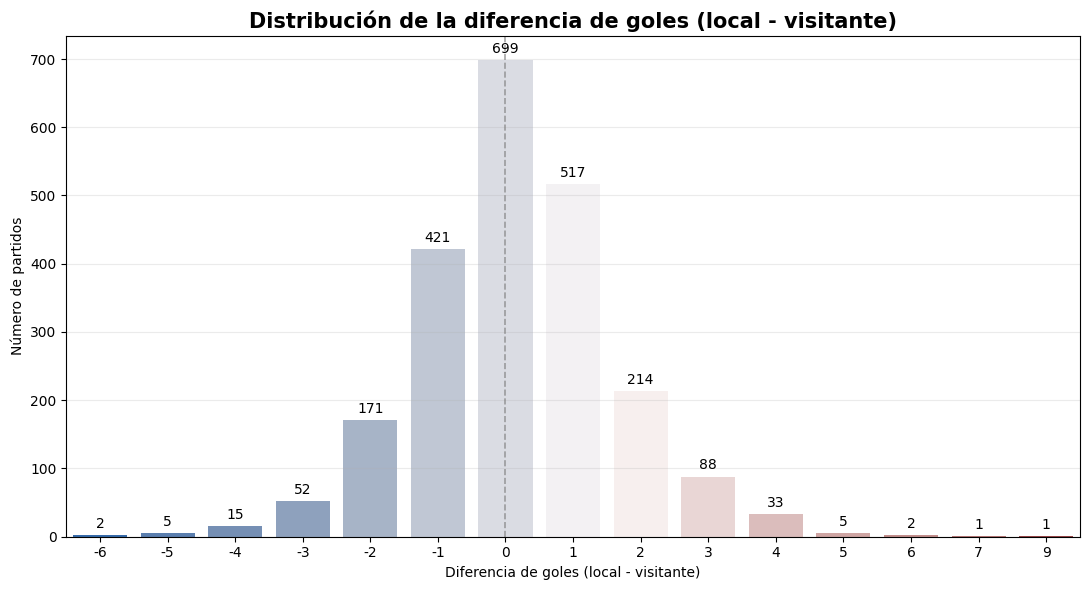

Figura guardada en: C:\Users\ADMIN003\OneDrive - Universidad Tecnológica de Panamá\Escritorio\II SEMESTRE 2026\TESIS\Sistema_Predictivo_LPF\figures\distribucion_diferencia_goles.png


In [43]:
# crear la figura y los ejes para la grafica
fig, ax = plt.subplots(
    figsize=(11, 6)
)

# aplicar una paleta divergente para diferenciar victorias visitantes, empates y victorias locales
sns.barplot(
    data=distribucion_diferencia,
    x="diferencia_goles",
    y="partidos",
    palette="vlag",
    hue="diferencia_goles",
    legend=False,
    ax=ax
)

# agregar el titulo y las etiquetas de los ejes
ax.set_title(
    "Distribución de la diferencia de goles (local - visitante)",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Diferencia de goles (local - visitante)")
ax.set_ylabel("Número de partidos")

# agregar una linea vertical tenue en cero para marcar el punto de empate
if 0 in distribucion_diferencia["diferencia_goles"].values:
    posicion_cero = distribucion_diferencia["diferencia_goles"].tolist().index(0)
    ax.axvline(
        x=posicion_cero,
        color="#7f7f7f",
        linestyle="--",
        linewidth=1.2,
        alpha=0.7
    )

# colocar la cantidad exacta de partidos sobre cada barra
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%d",
        padding=3,
        fontsize=10
    )

# configurar la cuadricula suave en el eje y
ax.grid(
    axis="y",
    alpha=0.25
)

plt.tight_layout()

# definir la ruta para guardar la figura
RUTA_FIGURA = (
    FIGURES_DIR
    / "distribucion_diferencia_goles.png"
)

# guardar la figura en alta resolucion
plt.savefig(
    RUTA_FIGURA,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# confirmar la ruta de guardado
print(
    "Figura guardada en:",
    RUTA_FIGURA
)

## 5. Análisis del comportamiento por equipos
El análisis por equipos permite estudiar la participación histórica y el rendimiento relativo de los clubes presentes en el conjunto de datos. Debido a que algunos equipos han participado durante más temporadas que otros, se diferencia entre indicadores de volumen, como el número total de partidos disputados, e indicadores relativos, como el porcentaje de victorias, los puntos por partido y la diferencia promedio de goles.

## Celda 32. Transformación del dataset a perspectiva de equipo (long format)
En esta celda reestructuro el dataset para cambiar la unidad de análisis de "partido" a "desempeño individual por equipo". Duplico los registros derivando las perspectivas de local y visitante, mapeo los resultados a victorias, empates y derrotas (G, E, P), calculo los puntos asignados y la diferencia de goles, y consolido ambos DataFrames en df_equipos

In [44]:
# perspectiva del equipo local
df_local = pd.DataFrame({
    "fecha_partido": df_eda["fecha_partido"],
    "temporada": df_eda["temporada"],
    "equipo": df_eda["home_team_name"],
    "condicion": "Local",
    "goles_favor": df_eda["home_team_goal_count"],
    "goles_contra": df_eda["away_team_goal_count"]
})

df_local["resultado_equipo"] = (
    df_eda["resultado"]
    .map({
        "L": "G",
        "E": "E",
        "V": "P"
    })
)

# perspectiva del equipo visitante
df_visitante = pd.DataFrame({
    "fecha_partido": df_eda["fecha_partido"],
    "temporada": df_eda["temporada"],
    "equipo": df_eda["away_team_name"],
    "condicion": "Visitante",
    "goles_favor": df_eda["away_team_goal_count"],
    "goles_contra": df_eda["home_team_goal_count"]
})

df_visitante["resultado_equipo"] = (
    df_eda["resultado"]
    .map({
        "L": "P",
        "E": "E",
        "V": "G"
    })
)

# unir ambas perspectivas
df_equipos = pd.concat(
    [df_local, df_visitante],
    ignore_index=True
)

# puntos obtenidos en cada partido
df_equipos["puntos"] = (
    df_equipos["resultado_equipo"]
    .map({
        "G": 3,
        "E": 1,
        "P": 0
    })
)

df_equipos["diferencia_goles"] = (
    df_equipos["goles_favor"]
    - df_equipos["goles_contra"]
)

# mostrar dimensiones y equipos unicos
print(
    "Registros por perspectiva de equipo:",
    len(df_equipos)
)

print(
    "Equipos diferentes:",
    df_equipos["equipo"].nunique()
)

# visualizar los primeros 10 registros formateados
display(df_equipos.head(10))

Registros por perspectiva de equipo: 4452
Equipos diferentes: 20


,fecha_partido,temporada,equipo,condicion,goles_favor,goles_contra,resultado_equipo,puntos,diferencia_goles
0,2014-07-18,2014/2015,Atlético Chiriquí,Local,0,0,E,1,0
1,2014-07-18,2014/2015,San Francisco FC,Local,0,0,E,1,0
2,2014-07-18,2014/2015,Árabe Unido,Local,0,1,P,0,-1
3,2014-07-19,2014/2015,Chepo,Local,1,2,P,0,-1
4,2014-07-19,2014/2015,Chorrillo,Local,0,0,E,1,0
5,2014-07-25,2014/2015,CA Independiente de La Chorrera,Local,1,0,G,3,1
6,2014-07-25,2014/2015,Tauro,Local,0,1,P,0,-1
7,2014-07-26,2014/2015,Alianza,Local,1,0,G,3,1
8,2014-07-26,2014/2015,Plaza Amador,Local,1,2,P,0,-1
9,2014-07-27,2014/2015,Sporting San Miguelito,Local,2,0,G,3,2


# Celda 33. Resumen histórico acumulado por equipo
En esta celda agrupo el dataset df_equipos por club para calcular el historial acumulado en la LPF. Computo el total de partidos disputados, la cantidad de victorias, empates y derrotas, los goles a favor y en contra, la diferencia de gol y el total de puntos obtenidos, además de métricas derivadas como el porcentaje de victorias, el promedio de puntos por partido y la media de goles anotados y recibidos.

In [45]:
# agrupar por equipo y calcular metricas acumuladas de rendimiento
resumen_equipos = (
    df_equipos
    .groupby("equipo")
    .agg(
        partidos=("equipo", "size"),
        victorias=(
            "resultado_equipo",
            lambda x: (x == "G").sum()
        ),
        empates=(
            "resultado_equipo",
            lambda x: (x == "E").sum()
        ),
        derrotas=(
            "resultado_equipo",
            lambda x: (x == "P").sum()
        ),
        goles_favor=("goles_favor", "sum"),
        goles_contra=("goles_contra", "sum"),
        puntos=("puntos", "sum")
    )
    .reset_index()
)

# calcular diferencia de goles acumulada
resumen_equipos["diferencia_goles"] = (
    resumen_equipos["goles_favor"]
    - resumen_equipos["goles_contra"]
)

# calcular porcentaje de victorias
resumen_equipos["porcentaje_victorias"] = (
    resumen_equipos["victorias"]
    / resumen_equipos["partidos"]
    * 100
).round(2)

# calcular promedio de puntos por partido
resumen_equipos["puntos_por_partido"] = (
    resumen_equipos["puntos"]
    / resumen_equipos["partidos"]
).round(3)

# calcular promedio de goles a favor por partido
resumen_equipos["goles_favor_promedio"] = (
    resumen_equipos["goles_favor"]
    / resumen_equipos["partidos"]
).round(3)

# calcular promedio de goles en contra por partido
resumen_equipos["goles_contra_promedio"] = (
    resumen_equipos["goles_contra"]
    / resumen_equipos["partidos"]
).round(3)

# mostrar la tabla ordenada por mayor cantidad de partidos disputados
display(
    resumen_equipos.sort_values(
        "partidos",
        ascending=False
    )
)

,equipo,partidos,victorias,empates,derrotas,goles_favor,goles_contra,puntos,diferencia_goles,porcentaje_victorias,puntos_por_partido,goles_favor_promedio,goles_contra_promedio
14,Tauro,421,176,128,117,529,406,656,123,41.81,1.558,1.257,0.964
10,Plaza Amador,421,184,132,105,546,387,684,159,43.71,1.625,1.297,0.919
19,Árabe Unido,409,158,121,130,462,398,595,64,38.63,1.455,1.130,0.973
11,San Francisco FC,406,141,130,135,465,437,553,28,34.73,1.362,1.145,1.076
13,Sporting San Miguelito,404,132,139,133,447,437,535,10,32.67,1.324,1.106,1.082
0,Alianza,400,133,113,154,409,456,512,-47,33.25,1.280,1.022,1.140
4,CA Independiente de La Chorrera,343,147,95,101,476,365,536,111,42.86,1.563,1.388,1.064
16,Universitario,250,78,76,96,270,321,310,-51,31.20,1.240,1.080,1.284
9,Herrera,191,46,68,77,213,264,206,-51,24.08,1.079,1.115,1.382
7,Costa del Este,190,57,69,64,212,221,240,-9,30.00,1.263,1.116,1.163


 # Celda 34. Participación histórica de los equipos en la LPF
En esta celda grafico la participación histórica de los equipos según la cantidad total de partidos disputados en la LPF. Aplico un degradado de color para destacar a las instituciones con mayor continuidad en el torneo, incluyo etiquetas numéricas con el total de encuentros sobre cada barra y guardo la figura generada en alta resolución.

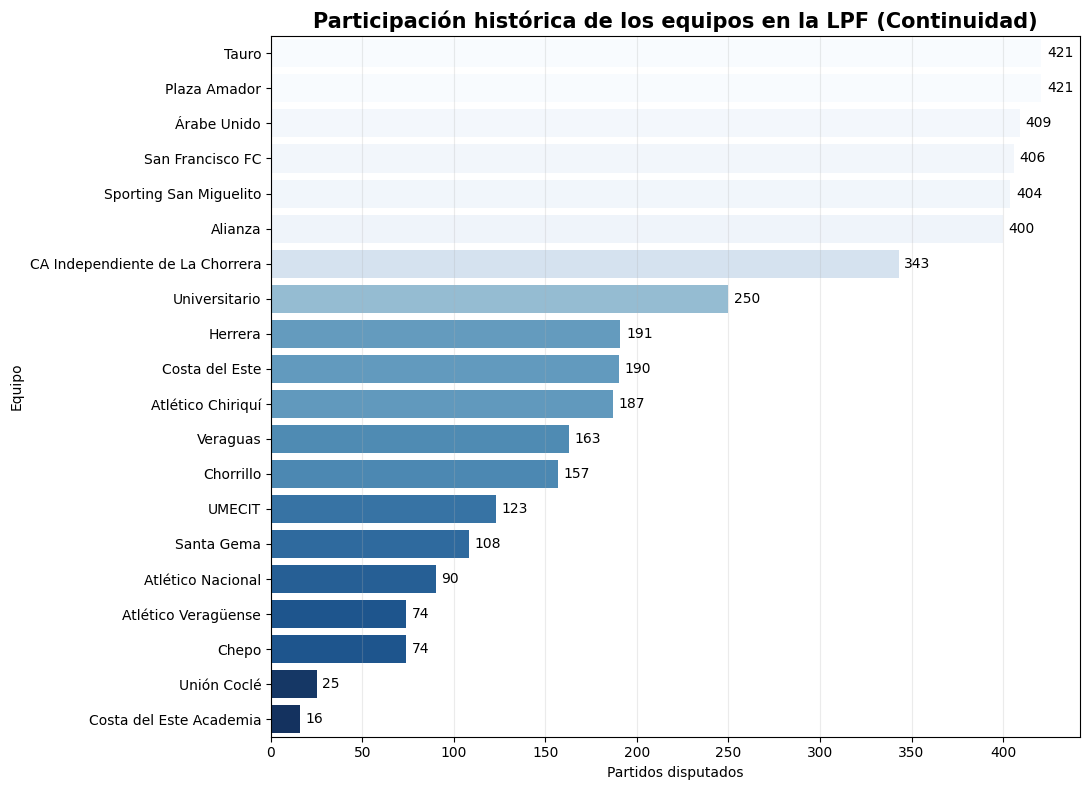

Figura guardada en: C:\Users\ADMIN003\OneDrive - Universidad Tecnológica de Panamá\Escritorio\II SEMESTRE 2026\TESIS\Sistema_Predictivo_LPF\figures\participacion_historica_equipos.png


In [46]:
# ordenar el dataframe por partidos disputados de mayor a menor
equipos_participacion = (
    resumen_equipos
    .sort_values(
        "partidos",
        ascending=False
    )
)

# crear la figura y los ejes para la grafica horizontal
fig, ax = plt.subplots(
    figsize=(11, 8)
)

# dibujar el grafico de barras horizontales con paleta degradada
sns.barplot(
    data=equipos_participacion,
    y="equipo",
    x="partidos",
    palette="Blues_r",
    hue="partidos",
    legend=False,
    ax=ax
)

# agregar el titulo y las etiquetas de los ejes
ax.set_title(
    "Participación histórica de los equipos en la LPF (Continuidad)",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Partidos disputados")
ax.set_ylabel("Equipo")

# colocar la cantidad exacta de partidos al final de cada barra
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%d",
        padding=4,
        fontsize=10
    )

# agregar cuadricula suave en el eje x
ax.grid(
    axis="x",
    alpha=0.25
)

plt.tight_layout()

# definir la ruta para guardar la figura
RUTA_FIGURA = (
    FIGURES_DIR
    / "participacion_historica_equipos.png"
)

# guardar la figura en alta resolucion
plt.savefig(
    RUTA_FIGURA,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# confirmar la ruta de guardado
print(
    "Figura guardada en:",
    RUTA_FIGURA
)

# Celda 35. Rendimiento relativo con umbral mínimo de partidos
En esta celda aplico un filtro sobre el dataset acumulado para conservar únicamente aquellos equipos que cumplen con un umbral mínimo de partidos disputados (MIN_PARTIDOS = 100). De esta manera evito distorsiones estadísticas causadas por muestras pequeñas y garantizo una comparación equitativa del rendimiento histórico en la LPF.

In [47]:
# definir el umbral minimo de partidos para la comparativa de rendimiento
MIN_PARTIDOS = 100

# filtrar los equipos que superan o igualan el umbral establecido
equipos_comparables = (
    resumen_equipos[
        resumen_equipos["partidos"]
        >= MIN_PARTIDOS
    ]
    .copy()
)

# mostrar la cantidad de equipos que cumplen el criterio
print(
    "Equipos con al menos",
    MIN_PARTIDOS,
    "partidos:",
    len(equipos_comparables)
)

Equipos con al menos 100 partidos: 15


In [48]:
ranking_ppg = (
    equipos_comparables
    .sort_values(
        "puntos_por_partido",
        ascending=False
    )
)

display(
    ranking_ppg[
        [
            "equipo",
            "partidos",
            "victorias",
            "empates",
            "derrotas",
            "porcentaje_victorias",
            "puntos_por_partido",
            "diferencia_goles"
        ]
    ]
)

,equipo,partidos,victorias,empates,derrotas,porcentaje_victorias,puntos_por_partido,diferencia_goles
10,Plaza Amador,421,184,132,105,43.71,1.625,159
4,CA Independiente de La Chorrera,343,147,95,101,42.86,1.563,111
14,Tauro,421,176,128,117,41.81,1.558,123
19,Árabe Unido,409,158,121,130,38.63,1.455,64
6,Chorrillo,157,56,55,46,35.67,1.420,21
11,San Francisco FC,406,141,130,135,34.73,1.362,28
13,Sporting San Miguelito,404,132,139,133,32.67,1.324,10
0,Alianza,400,133,113,154,33.25,1.280,-47
7,Costa del Este,190,57,69,64,30.00,1.263,-9
16,Universitario,250,78,76,96,31.20,1.240,-51


# Celda 36. Gráfica de promedio de puntos por partido (PPP)
En esta celda grafico el promedio de puntos por partido (PPP) para los equipos que superan el umbral mínimo de encuentros (MIN_PARTIDOS). Ordeno la visualización de mayor a menor rendimiento, aplico una paleta degradada para resaltar la jerarquía histórica en la LPF, coloco las etiquetas numéricas con tres decimales al final de cada barra y guardo la figura en la carpeta correspondiente.

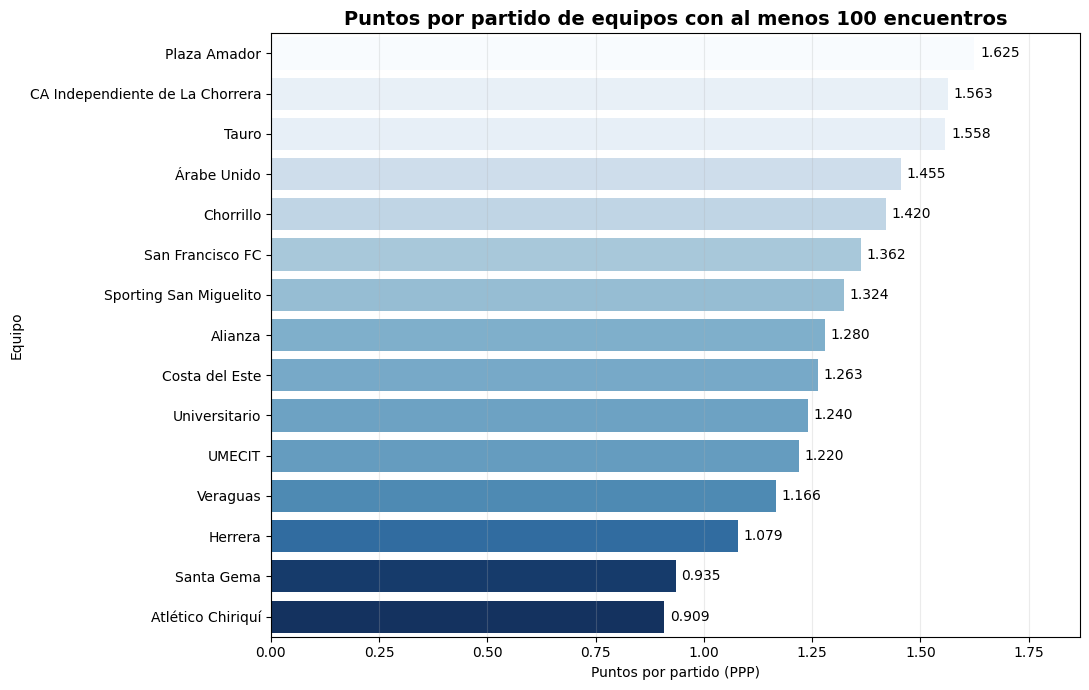

Figura guardada en: C:\Users\ADMIN003\OneDrive - Universidad Tecnológica de Panamá\Escritorio\II SEMESTRE 2026\TESIS\Sistema_Predictivo_LPF\figures\puntos_por_partido_equipos.png


In [49]:
# ordenar el ranking de equipos comparables por puntos por partido de mayor a menor
ranking_ppg = (
    equipos_comparables
    .sort_values(
        "puntos_por_partido",
        ascending=False
    )
    .reset_index(drop=True)
)

# crear la figura y los ejes para la grafica
fig, ax = plt.subplots(
    figsize=(11, 7)
)

# dibujar el grafico de barras horizontales aplicando paleta degradada
sns.barplot(
    data=ranking_ppg,
    y="equipo",
    x="puntos_por_partido",
    palette="Blues_r",
    hue="puntos_por_partido",
    legend=False,
    ax=ax
)

# agregar el titulo y las etiquetas de los ejes
ax.set_title(
    f"Puntos por partido de equipos con al menos {MIN_PARTIDOS} encuentros",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Puntos por partido (PPP)")
ax.set_ylabel("Equipo")

# ajustar el limite del eje x para dar espacio a las anotaciones
max_ppg = ranking_ppg["puntos_por_partido"].max()
ax.set_xlim(0, max_ppg * 1.15)

# colocar las etiquetas numericas formateadas a 3 decimales
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.3f",
        padding=4,
        fontsize=10
    )

# agregar cuadricula suave en el eje x
ax.grid(
    axis="x",
    alpha=0.25
)

plt.tight_layout()

# definir la ruta para guardar la figura
RUTA_FIGURA = (
    FIGURES_DIR
    / "puntos_por_partido_equipos.png"
)

# guardar la figura en alta resolucion
plt.savefig(
    RUTA_FIGURA,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# confirmar la ruta de guardado
print(
    "Figura guardada en:",
    RUTA_FIGURA
)

# Celda 37. Rendimiento por condición de localía a nivel de equipo
En esta celda analizo el rendimiento individual de cada equipo segregado por su condición de local y visitante. Agrupo df_equipos por club y condición para calcular los puntos acumulados, los goles anotados y recibidos, y derivo el promedio de puntos por partido (PPP) y la media de goles a favor bajo cada escenario. Esto me permite evaluar cómo se manifiesta la ventaja de localía a nivel institucional en la LPF.

In [50]:
# agrupar por equipo y condicion para desagregar el rendimiento
rendimiento_condicion = (
    df_equipos
    .groupby(
        ["equipo", "condicion"]
    )
    .agg(
        partidos=("equipo", "size"),
        puntos=("puntos", "sum"),
        goles_favor=("goles_favor", "sum"),
        goles_contra=("goles_contra", "sum")
    )
    .reset_index()
)

# calcular el promedio de puntos por partido segun condicion
rendimiento_condicion[
    "puntos_por_partido"
] = (
    rendimiento_condicion["puntos"]
    / rendimiento_condicion["partidos"]
).round(3)

# calcular el promedio de goles a favor por partido segun condicion
rendimiento_condicion[
    "goles_favor_promedio"
] = (
    rendimiento_condicion["goles_favor"]
    / rendimiento_condicion["partidos"]
).round(3)

# mostrar la tabla de rendimiento desglosada por localia
display(rendimiento_condicion)

,equipo,condicion,partidos,puntos,goles_favor,goles_contra,puntos_por_partido,goles_favor_promedio
0,Alianza,Local,201,289,219,218,1.438,1.090
1,Alianza,Visitante,199,223,190,238,1.121,0.955
2,Atlético Chiriquí,Local,94,107,81,120,1.138,0.862
3,Atlético Chiriquí,Visitante,93,63,76,178,0.677,0.817
4,Atlético Nacional,Local,45,43,40,75,0.956,0.889
5,Atlético Nacional,Visitante,45,51,49,68,1.133,1.089
6,Atlético Veragüense,Local,36,48,33,35,1.333,0.917
7,Atlético Veragüense,Visitante,38,30,34,66,0.789,0.895
8,CA Independiente de La Chorrera,Local,177,319,272,168,1.802,1.537
9,CA Independiente de La Chorrera,Visitante,166,217,204,197,1.307,1.229


In [53]:
ppg_condicion = (
    rendimiento_condicion
    .pivot(
        index="equipo",
        columns="condicion",
        values="puntos_por_partido"
    )
    .reset_index()
)

ppg_condicion["diferencia_localia"] = (
    ppg_condicion["Local"]
    - ppg_condicion["Visitante"]
)

display(
    ppg_condicion
    .sort_values(
        "diferencia_localia",
        ascending=False
    )
)

condicion,equipo,Local,Visitante,diferencia_localia
3,Atlético Veragüense,1.333,0.789,0.544
15,UMECIT,1.492,0.952,0.540
4,CA Independiente de La Chorrera,1.802,1.307,0.495
17,Unión Coclé,1.385,0.917,0.468
1,Atlético Chiriquí,1.138,0.677,0.461
9,Herrera,1.274,0.885,0.389
19,Árabe Unido,1.635,1.277,0.358
0,Alianza,1.438,1.121,0.317
18,Veraguas,1.325,1.012,0.313
12,Santa Gema,1.074,0.796,0.278


## 6. Análisis de valores atípicos y partidos extremos
Como parte final del análisis exploratorio, examino los encuentros con cantidades elevadas de goles o diferencias amplias en el marcador. El objetivo no es eliminar automáticamente estas observaciones, sino verificar que correspondan a resultados deportivos válidos y determinar su influencia potencial sobre los análisis posteriores.

# Celda 38. Auditoría de resultados extremos (goleadas y partidos con alta cuota goleadora)
En esta celda realizo una auditoría sobre el dataset df_eda para identificar atípicos u outliers caracterizados por marcadores abultados. Filtro aquellos encuentros que registraron un total de 6 o más goles o que finalizaron con una diferencia de gol igual o superior a 4 tantos. Esto me permite inspeccionar los partidos más atípicos de la LPF y validar la integridad de la información en los extremos de la distribución.

In [54]:
# filtrar partidos con alta cuota de goles (>= 6) o marcadores abultados (|diferencia| >= 4)
partidos_extremos = (
    df_eda.loc[
        (df_eda["total_goal_count"] >= 6)
        | (df_eda["diferencia_goles"].abs() >= 4),
        [
            "fecha_partido",
            "temporada",
            "home_team_name",
            "away_team_name",
            "home_team_goal_count",
            "away_team_goal_count",
            "total_goal_count",
            "diferencia_goles"
        ]
    ]
    .sort_values(
        ["total_goal_count", "diferencia_goles"],
        ascending=[False, False]
    )
)

# mostrar el total de encuentros atipicos detectados
print(
    "Partidos extremos detectados:",
    len(partidos_extremos)
)

# mostrar la tabla detallada de partidos extremos
display(partidos_extremos)

Partidos extremos detectados: 121


,fecha_partido,temporada,home_team_name,away_team_name,home_team_goal_count,away_team_goal_count,total_goal_count,diferencia_goles
1653,2023-10-29,2023,Herrera,Atlético Chiriquí,9,0,9,9
219,2015-08-23,2015/2016,Árabe Unido,Atlético Chiriquí,8,1,9,7
2106,2026-02-21,2026,Plaza Amador,Herrera,7,2,9,5
959,2020-01-31,2020,San Francisco FC,Plaza Amador,6,3,9,3
2107,2026-02-22,2026,Alianza,Veraguas,5,3,8,2
...,...,...,...,...,...,...,...,...
910,2019-03-30,2018/2019,Santa Gema,Alianza,0,4,4,-4
1433,2022-10-08,2022,Atlético Chiriquí,San Francisco FC,0,4,4,-4
1580,2023-08-12,2023,Árabe Unido,Tauro,0,4,4,-4
1726,2024-04-06,2024,Universitario,Plaza Amador,0,4,4,-4


# Celda 39. Frecuencia de marcadores extremos
En esta celda cuantifico la ocurrencia de partidos con marcadores atípicos o extremos en la LPF evaluando tres criterios clave: encuentros con 6 o más goles, partidos con una diferencia de gol igual o mayor a 4 tantos y goleadas excepcionales de 8 o más goles. Muestro el conteo de partidos y el porcentaje representativo sobre el total analizado para medir la probabilidad de eventos de alta dispersión ofensiva.

In [55]:
# resumir la frecuencia y porcentaje de marcadores extremos
resumen_extremos = pd.DataFrame({
    "criterio": [
        "6 o más goles",
        "Diferencia absoluta >= 4 goles",
        "8 o más goles"
    ],
    "partidos": [
        (df_eda["total_goal_count"] >= 6).sum(),
        (df_eda["diferencia_goles"].abs() >= 4).sum(),
        (df_eda["total_goal_count"] >= 8).sum()
    ]
})

# calcular el porcentaje respecto al total de partidos
resumen_extremos["porcentaje"] = (
    resumen_extremos["partidos"]
    / len(df_eda)
    * 100
).round(2)

# mostrar el resumen cuantitativo de eventos extremos
display(resumen_extremos)

,criterio,partidos,porcentaje
0,6 o más goles,72,3.23
1,Diferencia absoluta >= 4 goles,64,2.88
2,8 o más goles,8,0.36


# Celda 40. Diagnóstico de valores atípicos mediante el Rango Intercuartílico (IQR)
En esta celda aplico el método del Rango Intercuartílico (IQR) sobre la variable de goles totales por partido

In [56]:
# calcular cuartiles e IQR para el total de goles
q1 = df_eda["total_goal_count"].quantile(0.25)
q3 = df_eda["total_goal_count"].quantile(0.75)

iqr = q3 - q1

# determinar limites superior e inferior del metodo IQR
limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

# imprimir resumen estadistico
print("Q1:", q1)
print("Q3:", q3)
print("IQR:", iqr)
print("Límite inferior:", limite_inferior)
print("Límite superior:", limite_superior)

# identificar los partidos que caen fuera de los limites
outliers_iqr = df_eda[
    (df_eda["total_goal_count"] < limite_inferior)
    | (df_eda["total_goal_count"] > limite_superior)
]

# mostrar el total de observaciones identificadas
print(
    "Partidos identificados por IQR:",
    len(outliers_iqr)
)

Q1: 1.0
Q3: 3.0
IQR: 2.0
Límite inferior: -2.0
Límite superior: 6.0
Partidos identificados por IQR: 25


# Celda 41. Auditoría de períodos parciales y comportamientos por temporada
En esta celda analizo la consistencia de las métricas a lo largo de las distintas temporadas del dataset para identificar posibles sesgos causados por períodos incompletos o atípicos. Agrupo df_eda por temporada para evaluar el total de partidos registrados, la media de goles totales y la distribución porcentual de los resultados finales (victorias locales, empates y victorias visitantes)

In [57]:
# agrupar por temporada para auditar volumen de partidos y distribucion de resultados
auditoria_periodos = (
    df_eda
    .groupby("temporada")
    .agg(
        partidos=("registro_id", "size"),
        goles_promedio=("total_goal_count", "mean"),
        victoria_local=(
            "resultado",
            lambda x: (x == "L").mean() * 100
        ),
        empate=(
            "resultado",
            lambda x: (x == "E").mean() * 100
        ),
        victoria_visitante=(
            "resultado",
            lambda x: (x == "V").mean() * 100
        )
    )
    .round(2)
    .reset_index()
)

# mostrar el reporte de auditoria por temporada
display(auditoria_periodos)

,temporada,partidos,goles_promedio,victoria_local,empate,victoria_visitante
0,2014/2015,190,2.29,35.79,31.05,33.16
1,2015/2016,190,2.18,45.26,26.84,27.89
2,2016/2017,190,2.08,37.89,28.42,33.68
3,2017/2018,189,2.13,42.86,34.39,22.75
4,2018/2019,194,2.28,35.57,28.87,35.57
5,2020,92,2.05,36.96,34.78,28.26
6,2021,206,1.99,35.44,36.41,28.16
7,2022,206,2.19,36.41,31.55,32.04
8,2023,206,2.47,42.23,28.16,29.61
9,2024,206,2.26,41.26,28.16,30.58


### 5.1. Vigencia competitiva de los equipos

El conjunto histórico incluye clubes que participaron en temporadas anteriores pero que no necesariamente forman parte de la composición más reciente de la LPF. Estos registros se conservan debido a su valor histórico y estadístico; sin embargo, se distingue entre los equipos presentes en el último periodo disponible y aquellos cuya participación corresponde únicamente a etapas anteriores.

Esta separación será utilizada posteriormente para limitar la selección de equipos en la interfaz predictiva sin eliminar información histórica utilizada durante el entrenamiento.

In [58]:
ULTIMO_PERIODO = "2026/2027"

equipos_ultimo_periodo = set(
    df_eda.loc[
        df_eda["temporada"].eq(ULTIMO_PERIODO),
        "home_team_name"
    ]
).union(
    set(
        df_eda.loc[
            df_eda["temporada"].eq(ULTIMO_PERIODO),
            "away_team_name"
        ]
    )
)

todos_equipos = sorted(
    set(df_eda["home_team_name"])
    .union(set(df_eda["away_team_name"]))
)

vigencia_equipos = pd.DataFrame({
    "equipo": todos_equipos
})

vigencia_equipos["estado_dataset"] = np.where(
    vigencia_equipos["equipo"].isin(
        equipos_ultimo_periodo
    ),
    "Presente en el último periodo",
    "Participación histórica"
)

display(
    vigencia_equipos.sort_values(
        ["estado_dataset", "equipo"]
    )
)

print(
    "Equipos presentes en el último periodo:",
    len(equipos_ultimo_periodo)
)

print(
    "Equipos exclusivamente históricos:",
    len(todos_equipos) - len(equipos_ultimo_periodo)
)

,equipo,estado_dataset
1,Atlético Chiriquí,Participación histórica
2,Atlético Nacional,Participación histórica
3,Atlético Veragüense,Participación histórica
5,Chepo,Participación histórica
6,Chorrillo,Participación histórica
7,Costa del Este,Participación histórica
8,Costa del Este Academia,Participación histórica
12,Santa Gema,Participación histórica
0,Alianza,Presente en el último periodo
4,CA Independiente de La Chorrera,Presente en el último periodo


Equipos presentes en el último periodo: 12
Equipos exclusivamente históricos: 8


In [59]:
resumen_equipos_vigencia = (
    resumen_equipos
    .merge(
        vigencia_equipos,
        on="equipo",
        how="left"
    )
)
display(
    resumen_equipos_vigencia[
        [
            "equipo",
            "partidos",
            "puntos_por_partido",
            "estado_dataset"
        ]
    ]
    .sort_values(
        "partidos",
        ascending=False
    )
)

,equipo,partidos,puntos_por_partido,estado_dataset
14,Tauro,421,1.558,Presente en el último periodo
10,Plaza Amador,421,1.625,Presente en el último periodo
19,Árabe Unido,409,1.455,Presente en el último periodo
11,San Francisco FC,406,1.362,Presente en el último periodo
13,Sporting San Miguelito,404,1.324,Presente en el último periodo
0,Alianza,400,1.280,Presente en el último periodo
4,CA Independiente de La Chorrera,343,1.563,Presente en el último periodo
16,Universitario,250,1.240,Presente en el último periodo
9,Herrera,191,1.079,Presente en el último periodo
7,Costa del Este,190,1.263,Participación histórica


# Celda 42. Resumen ejecutivo de métricas clave e indicadores del EDA
En esta celda consolido los principales hallazgos del Análisis Exploratorio de Datos (EDA) en un DataFrame sintético. Compilo métricas fundamentales como el volumen total de partidos y clubes analizados, la distribución de goles (locales, visitantes y totales), el desglose porcentual de resultados finales (L, E, V), la exactitud del modelo base o baseline accuracy y los índices de dispersión para la validación del supuesto de Poisson.

In [60]:
# compilar las metricas e indicadores clave del EDA
resumen_eda = pd.DataFrame({
    "Indicador": [
        "Partidos analizados",
        "Equipos identificados",
        "Promedio total de goles",
        "Promedio goles local",
        "Promedio goles visitante",
        "Victorias locales (%)",
        "Empates (%)",
        "Victorias visitantes (%)",
        "Accuracy baseline (%)",
        "Índice dispersión goles local",
        "Índice dispersión goles visitante"
    ],
    "Valor": [
        len(df_eda),
        df_equipos["equipo"].nunique(),
        round(df_eda["total_goal_count"].mean(), 3),
        round(df_eda["home_team_goal_count"].mean(), 3),
        round(df_eda["away_team_goal_count"].mean(), 3),
        round((df_eda["resultado"] == "L").mean() * 100, 2),
        round((df_eda["resultado"] == "E").mean() * 100, 2),
        round((df_eda["resultado"] == "V").mean() * 100, 2),
        round(baseline_accuracy * 100, 2),
        round(
            df_eda["home_team_goal_count"].var()
            / df_eda["home_team_goal_count"].mean(),
            3
        ),
        round(
            df_eda["away_team_goal_count"].var()
            / df_eda["away_team_goal_count"].mean(),
            3
        )
    ]
})

# mostrar la tabla de resumen ejecutivo del EDA
display(resumen_eda)

,Indicador,Valor
0,Partidos analizados,2226.000
1,Equipos identificados,20.000
2,Promedio total de goles,2.258
3,Promedio goles local,1.214
4,Promedio goles visitante,1.044
5,Victorias locales (%),38.680
6,Empates (%),31.400
7,Victorias visitantes (%),29.920
8,Accuracy baseline (%),38.680
9,Índice dispersión goles local,1.041
